# WD-GPR-SR: Wide-and-Deep-Kernel Gaussian Process Regression with Uncertainty-Weighted Symbolic Residual Correction for Li-ion Battery State-of-Health Estimation

**PBL Machine Learning, Problem Statement 2.** This notebook does the whole project in one go. It downloads the public NASA and CALCE battery data, extracts the health indicators, trains 15 baselines and our model with leave-one-cell-out testing and 3 seeds, runs the ablation study, explains the model (SHAP, LIME, PDP, ICE, ARD, symbolic sensitivities, permutation importance), and exports and times a small edge version. All numbers in the report come from here. Tables go to `results/` and plots to `results/figures/`.

**Sections**
1. Setup and configuration
2. Data download
3. Health-indicator extraction (NASA, CALCE)
4. Data audit and cleaning
5. Exploratory data analysis
6. Evaluation protocol
7. Baseline models
8. Proposed model: WD-GPR-SR
9. Training and evaluation of all models
10. Results and comparison
11. Ablation study
12. Explainability (XAI)
13. Error analysis and robustness to sensor noise
14. Edge deployment export and benchmark
15. Reproducibility record

## Revision note (version 2)
This is the second version of the notebook. The first full run (same data, protocol and seeds) had three problems:

1. **The GP had not finished training.** Its noise started at gpytorch's default of 0.69 (in standardised units) with learning rate 0.01, and it did not come down far enough in 400 steps. The 95 % intervals ended up 13-17 SOH points wide and covered about 100 % of points. Now the noise starts at 0.01 and the learning rate is 0.05 for the kernel, likelihood and variational parameters (0.01 for the neural feature map). I also tried 800 steps, but then the deep kernel overfits, so I kept 400.
2. **There was no calibration step.** Version 2 adds a one-number recalibration of the uncertainty, estimated from cross-fitted residuals on the training cells (section 8). Ablation A7 shows what it does.
3. **The deep branch was always on.** On the almost-linear CALCE-CS2 data the wide branch alone was better. Now inner cross-validation on the training cells picks either the Wide-and-Deep kernel or the wide-only kernel.

I made these changes after seeing the version-1 results, which included the test cells. Every new choice (noise, branch, calibration scale, shrinkage) is still made on training cells only, so no test data is used for fitting or selection. I also made the symbolic-regression search smaller (500x15 to 300x10 programs) so the run fits in one Colab session; the standalone SR baseline uses the same setting.

## 0. Problem definition (written before any experiment)
**Problem.** From the health indicators of one charge and the partial discharge after it, estimate the state of health (SOH, % of rated capacity) of a Li-ion cell, with a 95 % prediction interval. The cell is **never seen in training**, and the model has to be small enough for an edge device.

* **Input / output:** 6 health indicators per cycle in; SOH (%) and its standard deviation out.
* **Cells:** commercial LiCoO2-type cells, CC-CV charging at room temperature (NASA 18650 cells; CALCE CS2 and CX2 prismatic cells at 1C).
* **Rules:** only other cells may be used for training or tuning, and the model must export to a fixed-size form.
* **Main metric:** RMSE in SOH % on the unseen cells (leave-one-cell-out), mean ± std over 3 seeds. I also report MAE, R², MAPE, NLL, PICP95, MPIW95, equation size, latency and model size.

**Hypotheses**
* **H1:** the Wide-and-Deep GP has a lower unseen-cell RMSE than the exact GPRs and the plain deep-kernel GP, because the wide branch keeps it stable on a new cell.
* **H2:** the symbolic correction lowers RMSE further, or the shrinkage factor λ switches it off when it does not generalise.
* **H3:** the 95 % interval is calibrated (PICP95 between 90 % and 99 %) and not uselessly wide.

**When do I call it a success?** On a dataset, if WD-GPR-SR has the lowest RMSE of the probabilistic models, is within one seed-std of the best non-probabilistic baseline, and meets H3. Sections 10 and 11 say for each hypothesis whether it held.

## 1. Setup and configuration
On Colab this installs the three packages Colab does not have (gpytorch, gplearn, lime). Everything runs on the CPU so the results come out the same every time.

In [2]:
import os, sys, io, time, json, random, pickle, zipfile, urllib.request, warnings, platform, tracemalloc
from pathlib import Path

if 'google.colab' in sys.modules:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gpytorch', 'gplearn', 'lime'], check=True)

import numpy as np
import pandas as pd
import scipy
import scipy.io as sio
from scipy.ndimage import gaussian_filter1d
from scipy.signal import medfilt
from scipy.stats import spearmanr, wilcoxon
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as Fnn
import gpytorch
import sklearn
import xgboost
import shap
import sympy as sp
import gplearn
from gplearn.genetic import SymbolicRegressor
from lime.lime_tabular import LimeTabularExplainer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, ConstantKernel
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 9})

# PBL_QUICK=1 only checks that the code runs; all reported numbers use the full settings below.
QUICK = os.environ.get('PBL_QUICK') == '1'
SEEDS = [0] if QUICK else [0, 1, 2]
GP_EPOCHS = 40 if QUICK else 400          # Adam steps for each sparse GP
GP_LR = float(os.environ.get('PBL_GP_LR', 0.05))     # learning rate for kernel, likelihood and variational parameters
PHI_LR = 0.01                                          # learning rate for the small feature network
GP_NOISE_INIT = float(os.environ.get('PBL_NOISE0', 0.01))  # in standardised units; with gpytorch's default (0.69) the noise is still far too high after 400 steps
N_INDUCING = 64
NN_MAX_EPOCHS = 8 if QUICK else 300       # at most this many; early stopping on the inner validation cell decides
NN_PATIENCE = 20
NN_BATCH = 128
NN_LR = 2e-3
SEQ_LEN = 10                              # BiLSTM sees this cycle and the 9 before it, from the same cell
SR_POP, SR_GEN = (100, 2) if QUICK else (300, 10)
SR_PARSIMONY = 0.005
TUNE_GRID = [dict(p=2, wd=1e-4), dict(p=2, wd=1e-2), dict(p=4, wd=1e-4), dict(p=4, wd=1e-2)]

ROOT = Path.cwd()
DATA = ROOT / 'data'
RES = ROOT / 'results'
FIG = RES / 'figures'
EDGE = RES / 'edge'
for p in (DATA, RES, FIG, EDGE):
    p.mkdir(parents=True, exist_ok=True)

torch.set_default_dtype(torch.float64)
torch.use_deterministic_algorithms(True)


def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


T_START = time.time()
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__,
            'scikit-learn': sklearn.__version__, 'torch': torch.__version__, 'gpytorch': gpytorch.__version__,
            'xgboost': xgboost.__version__, 'shap': shap.__version__, 'gplearn': gplearn.__version__, 'sympy': sp.__version__,
            'platform': platform.platform(), 'processor': platform.processor() or platform.machine(), 'cpu_count': os.cpu_count()}
print('QUICK smoke-test mode' if QUICK else 'FULL run', '| seeds', SEEDS)
print(json.dumps(VERSIONS, indent=1))

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


FULL run | seeds [0, 1, 2]
{
 "python": "3.13.18",
 "numpy": "2.4.6",
 "pandas": "2.2.3",
 "scipy": "1.16.3",
 "scikit-learn": "1.9.1",
 "torch": "2.14.1+cpu",
 "gpytorch": "1.15.2",
 "xgboost": "3.4.1",
 "shap": "0.54.1",
 "gplearn": "0.4.3",
 "sympy": "1.14.0",
 "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
 "processor": "x86_64",
 "cpu_count": 2
}


## 2. Data download
* **NASA Ames Prognostics Center of Excellence, Li-ion Battery Aging Data** (Saha & Goebel, 2007): 18650 cells B0005, B0006, B0007 and B0018, rated 2.0 Ah, at 24 °C. They are charged at 1.5 A constant current (CC) to 4.2 V, then held at constant voltage (CV) until the current drops to 20 mA, and discharged at 2 A.
* **CALCE battery data, CS2 cells** (University of Maryland; He et al., 2011): prismatic LiCoO2 cells CS2_35 to CS2_38, rated 1.1 Ah. These are the 4 of CALCE's 15 CS2 cells that were cycled at a constant 1C with full cycles; the others use 0.5C, changing currents, random cut-off voltages or partial cycles. Charge at 0.55 A CC to 4.2 V, then CV to 0.05 A; discharge at 1.1 A (1C) to 2.7 V.
* **CALCE battery data, CX2 cells**: prismatic LiCoO2 cells, rated 1.35 Ah, charged at 0.675 A CC to 4.2 V, then CV. CALCE lists 12 CX2 cells under different protocols: constant 0.5C (CX2_16, 31, 33, 35), constant 1C (CX2_34, 36, 37, 38), 3C (CX2_8), changing temperature (CX2_4) and pulsed discharge (CX2_3, 32). I use only the four 1C cells (1.35 A), the same rate as CS2, because the discharge rate and temperature change both the capacity label and the health indicators.

The files are downloaded once and kept in `data/`.

In [3]:
NASA_URL = 'https://phm-datasets.s3.amazonaws.com/NASA/5.+Battery+Data+Set.zip'
CALCE_URL = 'https://web.calce.umd.edu/batteries/data/{}.zip'
NASA_CELLS = ['B0005', 'B0006', 'B0007', 'B0018']
CALCE_CELLS = ['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38']
CX2_CELLS = ['CX2_34', 'CX2_36', 'CX2_37', 'CX2_38']  # the four CX2 cells run at a constant 1C (1.35 A); the other 8 CALCE CX2 cells were tested differently


def fetch(url, dst):
    if not dst.exists():
        print('downloading', url)
        urllib.request.urlretrieve(url, dst)
    return dst


if not all((DATA / 'nasa' / f'{c}.mat').exists() for c in NASA_CELLS):
    outer = zipfile.ZipFile(fetch(NASA_URL, DATA / 'nasa_battery.zip'))
    inner = next(n for n in outer.namelist() if 'FY08Q4' in n)
    zipfile.ZipFile(io.BytesIO(outer.read(inner))).extractall(DATA / 'nasa')
for c in CALCE_CELLS + CX2_CELLS:
    if not (DATA / 'calce' / c).exists():
        zipfile.ZipFile(fetch(CALCE_URL.format(c), DATA / f'{c}.zip')).extractall(DATA / 'calce')
print({c: (DATA / 'nasa' / f'{c}.mat').stat().st_size for c in NASA_CELLS})
print({c: len(list((DATA / 'calce' / c).glob('*.xlsx'))) for c in CALCE_CELLS + CX2_CELLS}, 'CALCE files per cell')

{'B0005': 15956874, 'B0006': 16028159, 'B0007': 16049460, 'B0018': 8502218}
{'CS2_35': 25, 'CS2_36': 26, 'CS2_37': 27, 'CS2_38': 28, 'CX2_34': 43, 'CX2_36': 48, 'CX2_37': 31, 'CX2_38': 47} CALCE files per cell


## 3. Health-indicator extraction
Each row is one full discharge cycle, and the target is **SOH = 100 × discharge capacity / rated capacity**. The health indicators (HIs) come from the charge just before the discharge, plus one part of the discharge. I chose all of them from battery knowledge before building any model:

| HI | Meaning |
|---|---|
| `cc_time` | Length of the CC charge (s); gets shorter as capacity fades |
| `cv_time` | Length of the CV phase until the current is below 0.05 A (s); gets longer as resistance grows |
| `ic_peak` | Height of the main incremental-capacity peak dQ/dV during the CC charge (Ah/V), between 3.87 and 4.15 V (CC charges start near 3.8 V), Gaussian-smoothed |
| `ic_peak_v` | Voltage of that peak (V); moves with polarisation |
| `plateau_time` | Time for the voltage to fall from 3.8 V to 3.5 V during discharge (s) |
| `temp_rise` (NASA) | Temperature rise of the cell during discharge (°C) |
| `ir` (CALCE) | Median internal resistance logged by the Arbin tester during discharge (Ω) |

`plateau_time` only uses the part of the discharge above 3.5 V, not the whole discharge to cut-off, so it needs only a partial discharge and is not the capacity label itself. The audit below shows how closely each HI follows the target.

In [4]:
I_CV_END = 0.05
IC_WINDOW = (3.87, 4.15)  # after the rest, CC charging starts near 3.8 V, so the window starts just above that
PLATEAU = (3.8, 3.5)
NASA_FEATS = ['cc_time', 'cv_time', 'ic_peak', 'ic_peak_v', 'plateau_time', 'temp_rise']
CALCE_FEATS = ['cc_time', 'cv_time', 'ic_peak', 'ic_peak_v', 'plateau_time', 'ir']
NAN_CHARGE = dict(cc_time=np.nan, cv_time=np.nan, ic_peak=np.nan, ic_peak_v=np.nan)


def ic_feature(t, v, i):
    q = np.concatenate([[0.0], np.cumsum(0.5 * (i[1:] + i[:-1]) * np.diff(t))]) / 3600.0
    vm = np.maximum.accumulate(v)
    keep = np.concatenate([[True], np.diff(vm) > 0])
    vm, q = vm[keep], q[keep]
    grid = np.arange(IC_WINDOW[0], IC_WINDOW[1], 0.005)
    if len(vm) < 10 or vm[0] > grid[0] or vm[-1] < grid[-1]:
        return np.nan, np.nan
    ic = gaussian_filter1d(np.gradient(np.interp(grid, vm, q), grid), sigma=3)
    k = int(np.argmax(ic))
    return ic[k], grid[k]


def plateau_time(t, v):
    hi, lo = np.flatnonzero(v <= PLATEAU[0]), np.flatnonzero(v <= PLATEAU[1])
    return t[lo[0]] - t[hi[0]] if len(hi) and len(lo) else np.nan


def nasa_charge(d):
    if d is None:
        return dict(NAN_CHARGE)
    t, v, i = (np.asarray(d[k], float) for k in ('Time', 'Voltage_measured', 'Current_measured'))
    if i.max() < 1.0:
        return dict(NAN_CHARGE)
    a = int(np.argmax(i > 1.0))
    reach = np.flatnonzero(v[a:] >= 4.195)
    if not len(reach):
        return dict(NAN_CHARGE)
    b = a + reach[0]
    end = np.flatnonzero(i[b:] < I_CV_END)
    if not len(end):
        return dict(NAN_CHARGE)
    ic, icv = ic_feature(t[a:b + 1], v[a:b + 1], i[a:b + 1])
    return dict(cc_time=t[b] - t[a], cv_time=t[b + end[0]] - t[b], ic_peak=ic, ic_peak_v=icv)


def load_nasa(cell):
    cyc = sio.loadmat(DATA / 'nasa' / f'{cell}.mat', simplify_cells=True)[cell]['cycle']
    rows, last = [], None
    for c in cyc:
        if c['type'] == 'charge':
            last = c['data']
        elif c['type'] == 'discharge':
            d = c['data']
            t = np.asarray(d['Time'], float)
            v = medfilt(np.asarray(d['Voltage_measured'], float), 5)
            T = np.asarray(d['Temperature_measured'], float)
            rows.append(dict(cell=cell, cycle=len(rows) + 1, **nasa_charge(last), plateau_time=plateau_time(t, v),
                             temp_rise=T.max() - T[0], capacity=float(d['Capacity'])))
            last = None  # one charge goes with one discharge
    return pd.DataFrame(rows)


def load_calce(cell, i_ch, i_dis):
    frames, seen, dup_files = [], set(), []
    for f in sorted((DATA / 'calce' / cell).glob('*.xlsx')):
        book = pd.read_excel(f, sheet_name=None)
        sheets = [s for k, s in book.items() if k.startswith('Channel')]
        if not sheets:  # for example a summary workbook with no logged data
            dup_files.append(f.name + ' (no data sheet)')
            continue
        d = pd.concat(sheets, ignore_index=True)
        key = (str(d['Date_Time'].iloc[0]), len(d))
        if key in seen:
            dup_files.append(f.name)
            continue
        seen.add(key)
        frames.append((pd.to_datetime(d['Date_Time'].iloc[0]), f.name, d))
    frames.sort(key=lambda x: x[0])
    rows, n_cycles, skipped = [], 0, 0
    for _, name, d in frames:
        for _, g in d.groupby('Cycle_Index', sort=True):
            n_cycles += 1
            st = dict(tuple(g.groupby('Step_Index')))
            ok = {2, 4, 7} <= st.keys()
            if ok:
                cc, cv, dis = st[2], st[4], st[7]
                ok = (abs(cc['Current(A)'].median() - i_ch) < 0.05 and abs(dis['Current(A)'].median() + i_dis) < 0.05
                      and dis['Voltage(V)'].iloc[-1] <= 2.75)
            if not ok:
                skipped += 1
                continue
            t = cc['Test_Time(s)'].to_numpy()
            ic, icv = ic_feature(t, cc['Voltage(V)'].to_numpy(), cc['Current(A)'].to_numpy())
            tc, td = cv['Test_Time(s)'].to_numpy(), dis['Test_Time(s)'].to_numpy()
            qd = dis['Discharge_Capacity(Ah)']
            rows.append(dict(cell=cell, cycle=n_cycles, cc_time=t[-1] - t[0], cv_time=tc[-1] - tc[0], ic_peak=ic, ic_peak_v=icv,
                             plateau_time=plateau_time(td, dis['Voltage(V)'].to_numpy()),
                             ir=dis['Internal_Resistance(Ohm)'].median(), capacity=qd.max() - qd.min(), file=name))
    info = dict(cell=cell, files=len(frames) + len(dup_files), skipped_files=', '.join(dup_files) or '-',
                cycles_logged=n_cycles, non_standard_cycles=skipped)
    return pd.DataFrame(rows), info


CX2_STRIDE = 2  # CX2 has ~1,500 cycles per cell; keeping every 2nd one keeps the exact GPRs fast (the rule ignores labels)
CACHE = DATA / 'features_v3.pkl'
if CACHE.exists():
    raw_nasa, raw_calce, raw_cx2, calce_info = pickle.loads(CACHE.read_bytes())
else:
    raw_nasa = pd.concat([load_nasa(c) for c in NASA_CELLS], ignore_index=True)
    parts = [load_calce(c, 0.55, 1.1) for c in CALCE_CELLS] + [load_calce(c, 0.675, 1.35) for c in CX2_CELLS]
    raw_calce = pd.concat([p[0] for p in parts[:len(CALCE_CELLS)]], ignore_index=True)
    raw_cx2 = pd.concat([p[0] for p in parts[len(CALCE_CELLS):]], ignore_index=True)
    calce_info = pd.DataFrame([p[1] for p in parts])
    CACHE.write_bytes(pickle.dumps((raw_nasa, raw_calce, raw_cx2, calce_info)))
n_cx2_parsed = len(raw_cx2)
raw_cx2 = raw_cx2[raw_cx2.groupby('cell').cumcount() % CX2_STRIDE == 0].reset_index(drop=True)
print('NASA raw rows', len(raw_nasa), '| CALCE-CS2 raw rows', len(raw_calce),
      f'| CALCE-CX2 raw rows {n_cx2_parsed} -> {len(raw_cx2)} after keeping every {CX2_STRIDE}nd cycle')
print(calce_info.to_string(index=False))

NASA raw rows 636 | CALCE-CS2 raw rows 3861 | CALCE-CX2 raw rows 6810 -> 3406 after keeping every 2nd cycle
  cell  files                       skipped_files  cycles_logged  non_standard_cycles
CS2_35     25                  CS2_35_2_4_11.xlsx            886                   21
CS2_36     26                                   -            976                   19
CS2_37     27                                   -           1043                   19
CS2_38     28                  CS2_38_2_4_11.xlsx           1032                   17
CX2_34     43 CX2_34_8_16_10.xlsx (no data sheet)           1736                   40
CX2_36     48                                   -           1971                   36
CX2_37     31                                   -           1281                   21
CX2_38     47                                   -           1961                   42


## 4. Data audit and cleaning
I set these rules before training and apply them the same way to every cell; nothing is fitted on a split.
1. **Duplicate files** (same start time and length) are dropped while reading (see the table above).
2. **Non-standard cycles** (CALCE characterisation tests, interrupted cycles) are dropped while reading.
3. **Missing HI**: if the charge was partial or cut short, the HI can't be computed and the row is dropped.
4. **Impossible values**: capacity ≤ 0 or SOH > 120 %.
5. **Label outliers**: SOH more than 5 points away from the centred 11-cycle rolling median of the same cell. Normal capacity recovery after a rest stays below 5 points, so it is not flagged. Outliers are **flagged, not dropped**: they are left out of every training fold, but each test cell is scored on all of its valid cycles, so no test row is removed because of its label.

In [5]:
def clean(raw, feats, nominal):
    """Drop rows where an HI could not be computed or the label is impossible.
    Label outliers are only flagged: they leave training folds but stay in every test cell."""
    df = raw.sort_values(['cell', 'cycle']).reset_index(drop=True).copy()
    df['soh'] = 100.0 * df['capacity'] / nominal
    bad_hi = df[feats].isna().any(axis=1)
    impossible = (df['capacity'] <= 0) | (df['soh'] > 120)
    med = df.groupby('cell')['soh'].transform(lambda s: s.rolling(11, center=True, min_periods=3).median())
    df['outlier'] = ((df['soh'] - med).abs() > 5.0) & ~impossible
    keep = ~(bad_hi | impossible)
    audit = pd.DataFrame({'raw_cycles': df.groupby('cell').size(), 'invalid_HI': bad_hi.groupby(df.cell).sum(),
                          'impossible': impossible.groupby(df.cell).sum(),
                          'outliers_flagged': (df.outlier & keep).groupby(df.cell).sum(), 'kept': keep.groupby(df.cell).sum()})
    out = df[keep].reset_index(drop=True)
    audit['soh_start'] = out.groupby('cell')['soh'].first().round(1)
    audit['soh_end'] = out.groupby('cell')['soh'].last().round(1)
    audit['duplicate_rows'] = out.groupby('cell').apply(lambda g: int(g.duplicated(feats + ['capacity']).sum()))
    return out, audit


nasa, audit_nasa = clean(raw_nasa, NASA_FEATS, 2.0)
calce, audit_calce = clean(raw_calce, CALCE_FEATS, 1.1)
cx2, audit_cx2 = clean(raw_cx2, CALCE_FEATS, 1.35)
DATASETS = {'NASA': dict(df=nasa, feats=NASA_FEATS, cells=NASA_CELLS, nominal=2.0),
            'CALCE-CS2': dict(df=calce, feats=CALCE_FEATS, cells=CALCE_CELLS, nominal=1.1),
            'CALCE-CX2': dict(df=cx2, feats=CALCE_FEATS, cells=CX2_CELLS, nominal=1.35)}
audit = pd.concat({'NASA': audit_nasa, 'CALCE-CS2': audit_calce, 'CALCE-CX2': audit_cx2})
audit.to_csv(RES / 'data_audit.csv')
print(audit.to_string())

card = pd.DataFrame([
    dict(dataset='NASA PCoE Li-ion Battery Aging', source='NASA Ames PCoE (data.nasa.gov)', licence='U.S. Government open data; cite Saha & Goebel 2007',
         cells=', '.join(NASA_CELLS), chemistry='18650 Li-ion, 2.0 Ah', rows=len(nasa), features=len(NASA_FEATS),
         soh_range=f"{nasa.soh.min():.1f}-{nasa.soh.max():.1f}%", group_variable='cell'),
    dict(dataset='CALCE CS2', source='CALCE, Univ. of Maryland', licence='free for research; cite He et al. 2011',
         cells=', '.join(CALCE_CELLS), chemistry='prismatic LiCoO2, 1.1 Ah', rows=len(calce), features=len(CALCE_FEATS),
         soh_range=f"{calce.soh.min():.1f}-{calce.soh.max():.1f}%", group_variable='cell'),
    dict(dataset='CALCE CX2 (1C cells)', source='CALCE, Univ. of Maryland', licence='free for research; cite He et al. 2011',
         cells=', '.join(CX2_CELLS), chemistry='prismatic LiCoO2, 1.35 Ah', rows=len(cx2), features=len(CALCE_FEATS),
         soh_range=f"{cx2.soh.min():.1f}-{cx2.soh.max():.1f}%", group_variable='cell')])
card.to_csv(RES / 'dataset_card.csv', index=False)
print(card.T.to_string())
print('\nMissing values after cleaning:', {k: int(v['df'][v['feats'] + ['soh']].isna().sum().sum()) for k, v in DATASETS.items()})
print('\nData dictionary (NASA)'); print(nasa[NASA_FEATS + ['soh']].describe().T.round(3).to_string())
print('\nData dictionary (CALCE-CS2)'); print(calce[CALCE_FEATS + ['soh']].describe().T.round(3).to_string())
print('\nData dictionary (CALCE-CX2)'); print(cx2[CALCE_FEATS + ['soh']].describe().T.round(3).to_string())

                  raw_cycles  invalid_HI  impossible  outliers_flagged  kept  soh_start  soh_end  duplicate_rows
          cell                                                                                                  
NASA      B0005          168           3           0                 0   165       92.3     66.3               0
          B0006          168           5           0                 0   163      101.3     58.7               0
          B0007          168           3           0                 0   165       94.0     71.6               0
          B0018          132           3           0                 0   129       92.2     67.1               0
CALCE-CS2 CS2_35         865          51           0                11   814      103.5     44.3               0
          CS2_36         957         152           0                11   805      104.1     42.7               0
          CS2_37        1024         138           0                14   886      103.2     42.7

## 5. Exploratory data analysis
The HIs were already fixed before this step, so these plots only describe the data; they were not used to pick features.

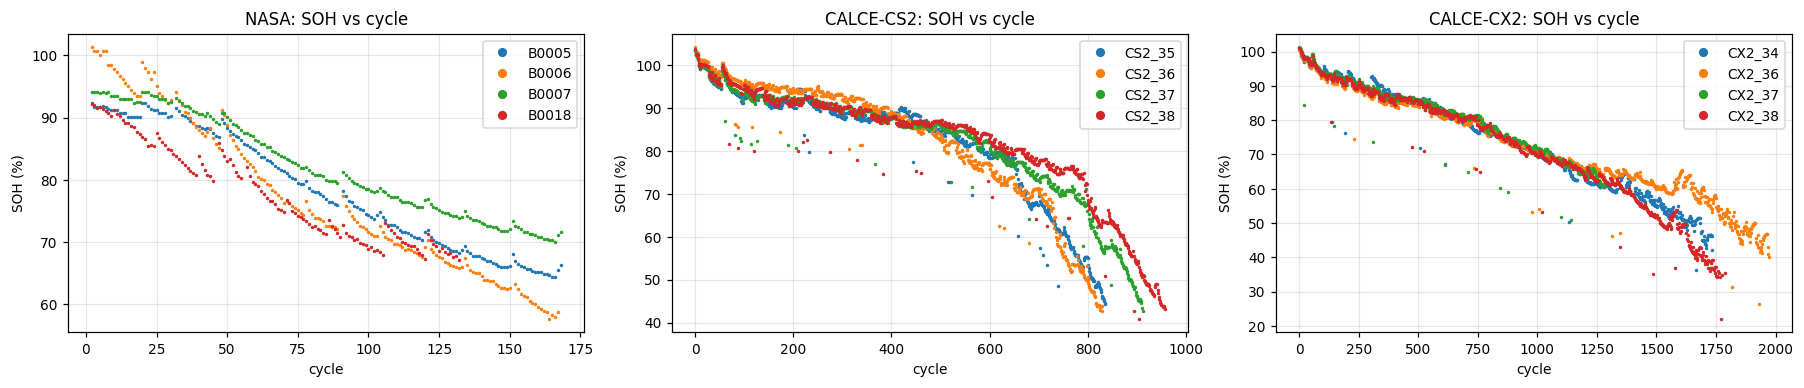

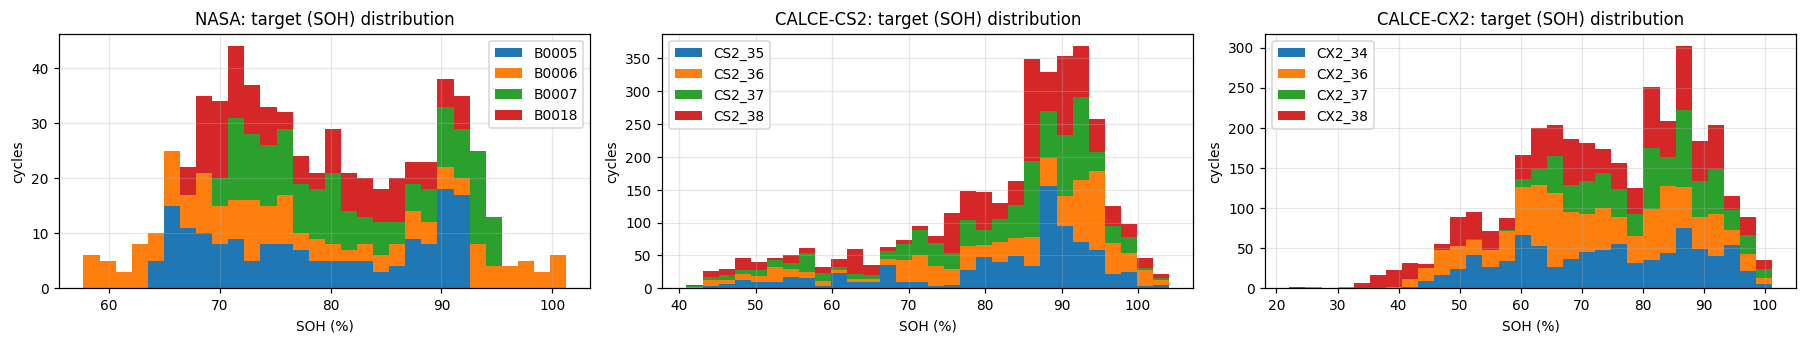

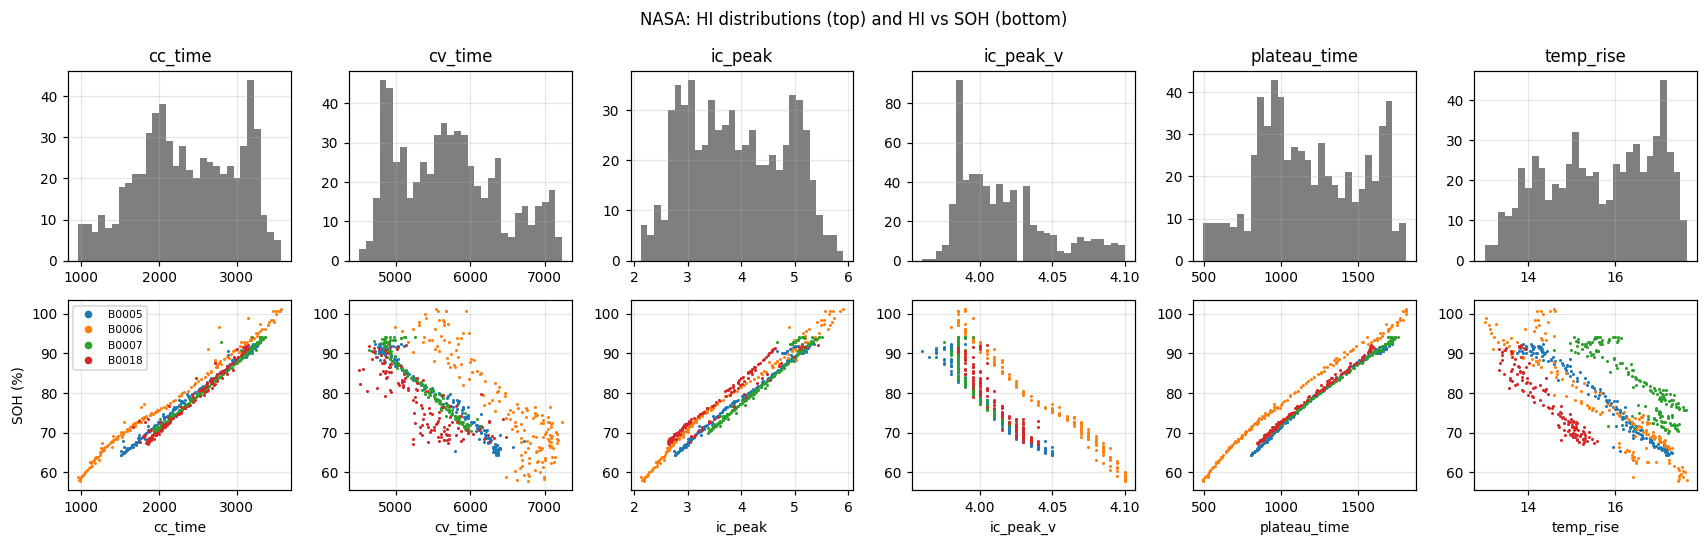

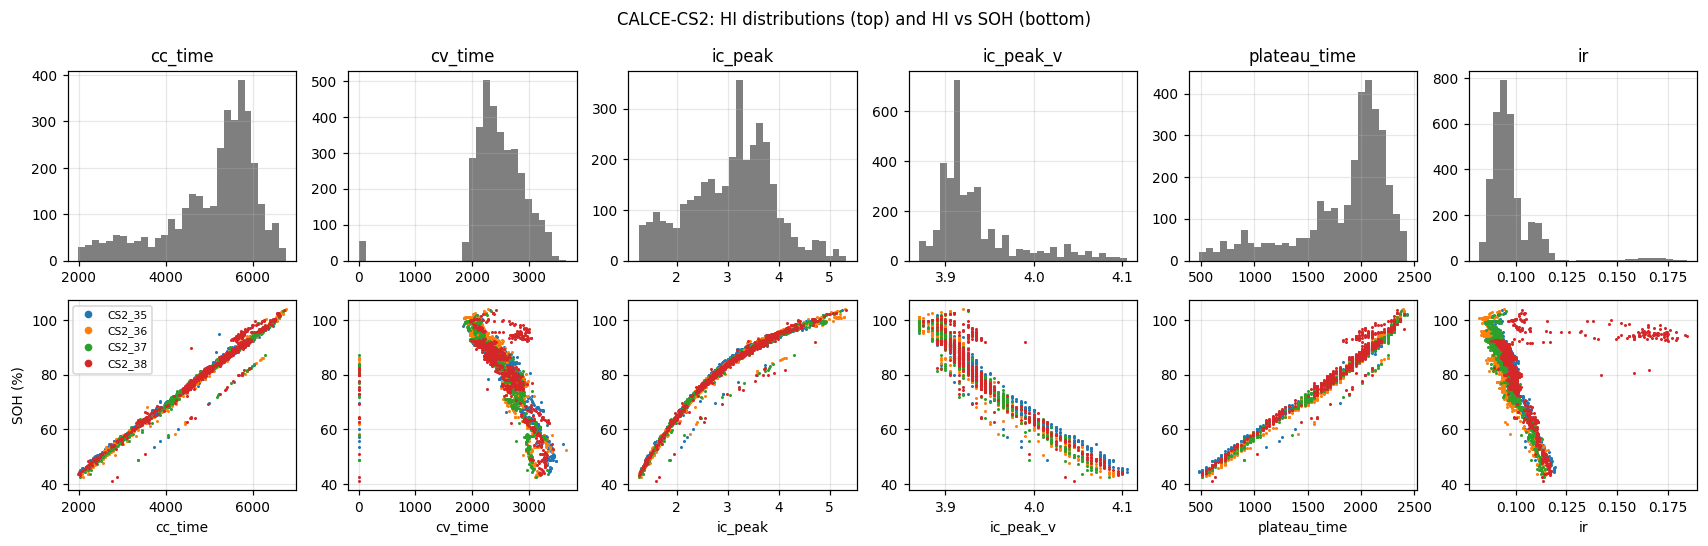

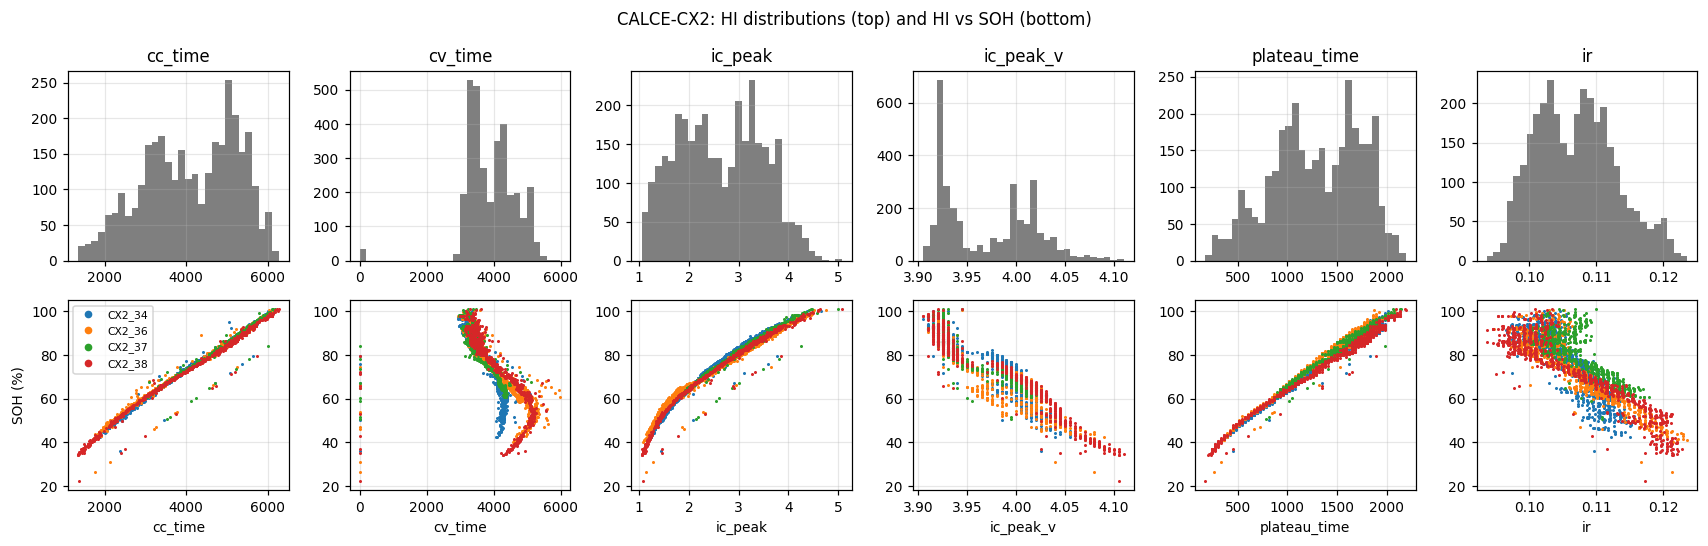

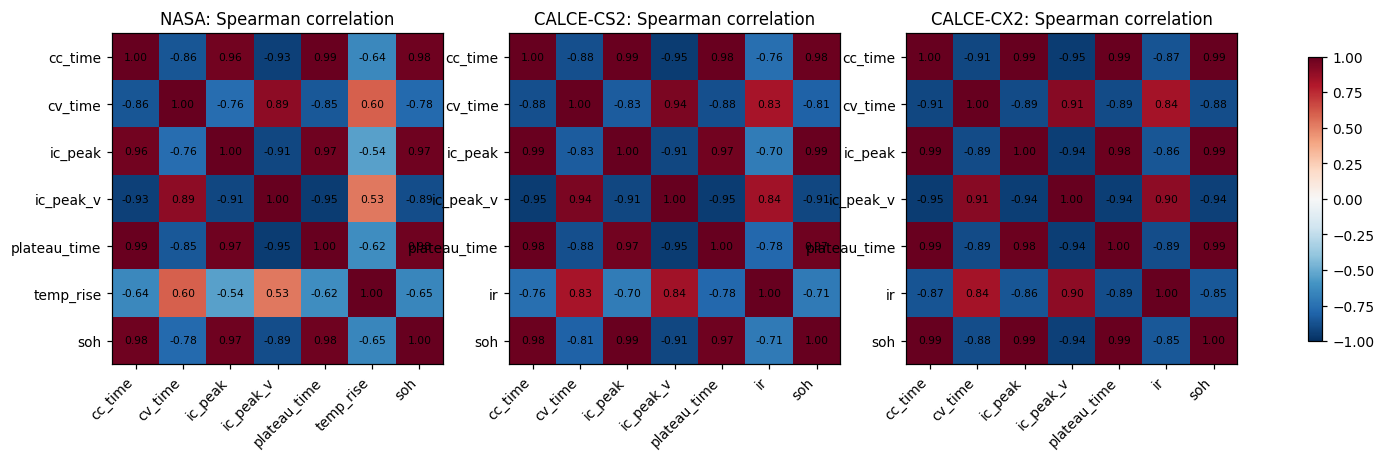

               NASA  CALCE-CS2  CALCE-CX2
cc_time       0.977      0.982      0.993
cv_time      -0.778     -0.812     -0.885
ic_peak       0.973      0.986      0.990
ic_peak_v    -0.887     -0.907     -0.937
ir              NaN     -0.706     -0.847
plateau_time  0.976      0.972      0.987
temp_rise    -0.651        NaN        NaN


In [6]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.5 * len(DATASETS), 3.6))
for ax, (name, ds) in zip(axes, DATASETS.items()):
    for c, g in ds['df'].groupby('cell'):
        ax.plot(g.cycle, g.soh, '.', ms=2.5, label=c)
    ax.set(title=f'{name}: SOH vs cycle', xlabel='cycle', ylabel='SOH (%)')
    ax.legend(markerscale=4)
savefig('eda_soh_curves')

fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.5 * len(DATASETS), 3.2))
for ax, (name, ds) in zip(axes, DATASETS.items()):
    ax.hist([g.soh for _, g in ds['df'].groupby('cell')], bins=30, stacked=True, label=ds['cells'])
    ax.set(title=f'{name}: target (SOH) distribution', xlabel='SOH (%)', ylabel='cycles')
    ax.legend()
savefig('eda_target_hist')

for name, ds in DATASETS.items():
    df, F = ds['df'], ds['feats']
    fig, axes = plt.subplots(2, len(F), figsize=(2.6 * len(F), 5))
    for j, f in enumerate(F):
        axes[0, j].hist(df[f], bins=30, color='tab:gray')
        axes[0, j].set(title=f, xlabel='')
        for c, g in df.groupby('cell'):
            axes[1, j].plot(g[f], g.soh, '.', ms=2, label=c)
        axes[1, j].set(xlabel=f, ylabel='SOH (%)' if j == 0 else '')
    axes[1, 0].legend(markerscale=4, fontsize=7)
    fig.suptitle(f'{name}: HI distributions (top) and HI vs SOH (bottom)')
    savefig(f'eda_features_{name}')

fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.5 * len(DATASETS), 4.2))
corr_tables = {}
for ax, (name, ds) in zip(axes, DATASETS.items()):
    cm = ds['df'][ds['feats'] + ['soh']].corr(method='spearman')
    corr_tables[name] = cm['soh'].drop('soh')
    im = ax.imshow(cm, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_xticks(range(len(cm)), cm.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(cm)), cm.columns)
    for a in range(len(cm)):
        for b in range(len(cm)):
            ax.text(b, a, f'{cm.iloc[a, b]:.2f}', ha='center', va='center', fontsize=7)
    ax.set_title(f'{name}: Spearman correlation')
    ax.grid(False)
plt.colorbar(im, ax=axes, shrink=0.8)
plt.savefig(FIG / 'eda_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print(pd.DataFrame(corr_tables).round(3).to_string())

**What the EDA shows**
* After cleaning, NASA keeps 622 of 636 cycles; the 14 removed had a partial or cut-off charge. CALCE-CS2 keeps 3,437 cycles; 51 to 152 per cell are removed because the CC charge started above the 3.87 V IC window or was incomplete. CALCE-CX2 keeps 3,284 of the every-2nd-cycle rows. Each CALCE cell has 6 to 20 flagged label outliers (NASA has none); they are left out of training folds only. No duplicate rows or missing values remain.
* Every cell loses capacity steadily, with small jumps back up after rest periods (easiest to see in NASA). The cells end at very different SOH: NASA between 58.7 % (B0006) and 71.6 % (B0007), CS2 near 43 %, and CX2 between 35.4 % (CX2_38) and 60.9 % (CX2_37).
* Because of this, a held-out cell can go below anything the training cells reached: B0006 goes below 66 % in NASA and CX2_38 below 40 % in CX2. So leave-one-cell-out includes real extrapolation, which is the case the wide (linear) branch is meant for.
* `cc_time`, `ic_peak` and `plateau_time` have Spearman |ρ| ≥ 0.97 with SOH in all three datasets; `ic_peak_v` and `cv_time` are strongly negative (−0.78 to −0.94). `temp_rise` (NASA, −0.65) and internal resistance (CALCE, −0.71 and −0.85) are weaker. The relations are close to linear, so I expect a linear model to be hard to beat. The HIs are also strongly correlated with each other, so SHAP, LIME and ARD may split importance between them differently; section 12 measures this.

## 6. Evaluation protocol (fixed before training)
* **Outer split: leave-one-cell-out (LOCO).** In each dataset every cell is the test cell once and the others are for training. This tests a battery the model has never seen, which is the real use case, and no cell has cycles on both sides of a split.
* **Inner validation: leave-one-cell-out on the training cells only.** Every hyperparameter, model choice and early-stopping point is picked this way. The test cell is not touched until the final prediction.
* **Preprocessing inside each fit.** Every scaler is fitted only on the training rows of its own fit (sklearn `Pipeline`s or the fit functions below).
* **Seeds.** 3 seeds (0, 1, 2). For each seed I pool the 4 test cells, then report mean ± std over the seeds. Models with no randomness (Mean, Ridge, SVR, the exact GPRs) give the same result every time, so their std is 0.
* **Metrics** (SOH in %): MAE, MSE, RMSE, R², MAPE; for models with uncertainty also Gaussian NLL, 95 % interval coverage (PICP) and mean interval width (MPIW).

In [7]:
def metrics(y, mu, sd=None):
    e = mu - y
    out = dict(MAE=np.abs(e).mean(), MSE=(e ** 2).mean())
    out['RMSE'] = np.sqrt(out['MSE'])
    out['R2'] = 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum()
    out['MAPE'] = 100 * np.mean(np.abs(e) / np.abs(y))
    if sd is not None:
        sd = np.maximum(sd, 1e-9)
        out['NLL'] = np.mean(0.5 * np.log(2 * np.pi * sd ** 2) + e ** 2 / (2 * sd ** 2))
        out['PICP95'] = 100 * np.mean(np.abs(e) <= 1.96 * sd)
        out['MPIW95'] = np.mean(2 * 1.96 * sd)
    return out


def split(ds_name, test_cell):
    ds = DATASETS[ds_name]
    df, F = ds['df'], ds['feats']
    tr, te = df[(df.cell != test_cell) & ~df.outlier], df[df.cell == test_cell]
    return dict(Xtr=tr[F].to_numpy(float), ytr=tr.soh.to_numpy(), gtr=tr.cell.to_numpy(),
                Xte=te[F].to_numpy(float), yte=te.soh.to_numpy(), gte=te.cell.to_numpy(), cyc=te.cycle.to_numpy())


def size_kb(obj):
    buf = io.BytesIO()
    if isinstance(obj, nn.Module):
        torch.save(obj.state_dict(), buf)
    else:
        pickle.dump(obj, buf)
    return buf.getbuffer().nbytes / 1024

## 7. Baseline models
| Family | Models | Why it is here |
|---|---|---|
| Naive | Mean predictor | The floor: any useful model has to beat it |
| Linear | Ridge | Shows how linear the HI-SOH relation is |
| Kernel / trees | SVR, Random Forest, XGBoost | Strong standard models for tables of numbers |
| Exact GPR | RBF, Matérn-5/2, ARD-RBF | Common SOH models that give uncertainty |
| Sparse GPR | SVGP with ARD-RBF, 64 inducing points | Same GP engine as our model, plain kernel |
| Deep-kernel GPR | SVGP with RBF on an MLP feature map | Standard DKL; our model without the wide branch and the SR stage |
| Neural | WideNN (1×256), DeepNN (4×64), Wide & Deep NN (linear + MLP) | Non-linear models with no uncertainty |
| Recurrent | BiLSTM over the last 10 cycles of the same cell | Uses the cell's recent history |
| Symbolic | Symbolic regression on its own (gplearn) | A readable equation without a GP |

Tuning: the sklearn models use `GridSearchCV` with inner leave-one-cell-out. The neural nets use early stopping on one inner validation cell and are then retrained on all training cells for that many epochs. DKL and WD-GPR-SR search the same grid (feature size, weight decay of the feature network) with inner LOCO.

In [8]:
SK_SPECS = {
    'Mean (naive)': (lambda s: DummyRegressor(), {}),
    'Linear (Ridge)': (lambda s: Ridge(), {'m__alpha': [0.1, 1.0, 10.0]}),
    'SVR': (lambda s: SVR(), {'m__C': [1, 10, 100], 'm__epsilon': [0.1, 0.5], 'm__gamma': ['scale', 0.1]}),
    'Random Forest': (lambda s: RandomForestRegressor(n_estimators=300, random_state=s, n_jobs=-1),
                      {'m__max_depth': [None, 8], 'm__min_samples_leaf': [1, 5]}),
    'XGBoost': (lambda s: XGBRegressor(n_estimators=400, learning_rate=0.05, random_state=s, n_jobs=2, tree_method='hist'),
                {'m__max_depth': [3, 5], 'm__subsample': [0.8, 1.0]}),
}
SK_GPR = ['GPR-RBF', 'GPR-Matern', 'GPR-ARD']
SEED_FREE = {'Mean (naive)', 'Linear (Ridge)', 'SVR', *SK_GPR}


def fit_sklearn(name, Xtr, ytr, gtr, seed):
    make, grid = SK_SPECS[name]
    pipe = Pipeline([('sc', StandardScaler()), ('m', make(seed))])
    if not grid:
        return pipe.fit(Xtr, ytr), {}, np.nan
    gs = GridSearchCV(pipe, grid, cv=LeaveOneGroupOut(), scoring='neg_root_mean_squared_error', n_jobs=1).fit(Xtr, ytr, groups=gtr)
    return gs.best_estimator_, gs.best_params_, -gs.best_score_


def fit_skgpr(name, Xtr, ytr):
    base = {'GPR-RBF': RBF(1.0), 'GPR-Matern': Matern(1.0, nu=2.5), 'GPR-ARD': RBF(np.ones(Xtr.shape[1]))}[name]
    gpr = GaussianProcessRegressor(ConstantKernel(1.0) * base + WhiteKernel(1e-2), normalize_y=True, random_state=0)
    return Pipeline([('sc', StandardScaler()), ('m', gpr)]).fit(Xtr, ytr)


class WideDeepNN(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.wide = nn.Linear(d, 1)
        self.deep = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x):
        return self.wide(x) + self.deep(x)


class BiLSTMReg(nn.Module):
    def __init__(self, d, h=32):
        super().__init__()
        self.lstm = nn.LSTM(d, h, batch_first=True, bidirectional=True)
        self.head = nn.Linear(2 * h, 1)

    def forward(self, x):
        _, (hn, _) = self.lstm(x)
        return self.head(torch.cat([hn[-2], hn[-1]], -1))


NN_SPECS = {
    'WideNN': lambda d: nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 1)),
    'DeepNN': lambda d: nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(),
                                      nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1)),
    'Wide&Deep NN': WideDeepNN,
    'BiLSTM': BiLSTMReg,
}


def windows(X, g, L=SEQ_LEN):
    """Window of past cycles for each row: row k sees cycles k-L+1..k of its own cell (the first cycle pads the start)."""
    out = np.empty((len(X), L, X.shape[1]))
    for c in np.unique(g):
        idx = np.flatnonzero(g == c)
        pad = np.concatenate([np.repeat(X[idx[:1]], L - 1, 0), X[idx]])
        for k, r in enumerate(idx):
            out[r] = pad[k:k + L]
    return out


def nn_predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.as_tensor(X)).squeeze(-1).numpy() * model.ys + model.ym


def train_nn(make, d, Xtr, ytr, Xva, yva, seed, epochs):
    set_seed(seed)
    model = make(d)
    opt = torch.optim.Adam(model.parameters(), lr=NN_LR, weight_decay=1e-5)
    model.ym, model.ys = ytr.mean(), ytr.std()
    X, y = torch.as_tensor(Xtr), torch.as_tensor((ytr - model.ym) / model.ys)
    gen = torch.Generator().manual_seed(seed)
    best, hist = (np.inf, epochs), []
    for ep in range(1, epochs + 1):
        model.train()
        for b in torch.randperm(len(X), generator=gen).split(NN_BATCH):
            opt.zero_grad()
            Fnn.mse_loss(model(X[b]).squeeze(-1), y[b]).backward()
            opt.step()
        if Xva is not None:
            va = np.sqrt(np.mean((nn_predict(model, Xva) - yva) ** 2))
            hist.append((ep, np.sqrt(np.mean((nn_predict(model, Xtr) - ytr) ** 2)), va))
            if va < best[0]:
                best = (va, ep)
            elif ep - best[1] >= NN_PATIENCE:
                break
    return model, best, hist


def fit_nn(name, f, seed):
    """Pick the epoch count by early stopping on one inner validation cell, then retrain on all training cells."""
    seq = name == 'BiLSTM'
    Xtr, ytr, gtr = f['Xtr'], f['ytr'], f['gtr']
    val = sorted(np.unique(gtr))[-1]
    m_in = gtr != val

    def prep(sc, X, g):
        Z = sc.transform(X)
        return windows(Z, g) if seq else Z

    sc = StandardScaler().fit(Xtr[m_in])
    _, (va_rmse, best_ep), hist = train_nn(NN_SPECS[name], Xtr.shape[1], prep(sc, Xtr[m_in], gtr[m_in]), ytr[m_in],
                                           prep(sc, Xtr[~m_in], gtr[~m_in]), ytr[~m_in], seed, NN_MAX_EPOCHS)
    sc = StandardScaler().fit(Xtr)
    model, _, _ = train_nn(NN_SPECS[name], Xtr.shape[1], prep(sc, Xtr, gtr), ytr, None, None, seed, best_ep)
    model.sc, model.seq = sc, seq
    return model, best_ep, va_rmse, hist, nn_predict(model, prep(sc, f['Xte'], f['gte']))


def make_sr(seed):
    return SymbolicRegressor(population_size=SR_POP, generations=SR_GEN, function_set=('add', 'sub', 'mul', 'div'),
                             init_depth=(2, 4), parsimony_coefficient=SR_PARSIMONY, random_state=seed, n_jobs=1)


SR_OPS = {'add': lambda a, b: a + b, 'sub': lambda a, b: a - b, 'mul': lambda a, b: a * b, 'div': lambda a, b: a / b}


def sr_to_sympy(sr, names):
    syms = {f'X{j}': sp.Symbol(f'z_{n}') for j, n in enumerate(names)}
    return sp.simplify(sp.sympify(str(sr._program), locals={**SR_OPS, **syms}))


def show_expr(expr, digits=4):
    return str(expr.xreplace({a: sp.Float(round(float(a), digits)) for a in expr.atoms(sp.Float)}))

## 8. Proposed model: WD-GPR-SR

**Wide-and-Deep kernel.** The HIs $x\in\mathbb{R}^d$ are standardised, and $\varphi_\theta:\mathbb{R}^d\to\mathbb{R}^p$ is a small MLP. The kernel is
$$k_{WD}(x,x') = \underbrace{\sum_{j=1}^{d} v_j\,x_j x'_j}_{\text{wide: ARD linear}} \;+\; \underbrace{s^2\exp\!\Big(-\tfrac12\big\|(\varphi_\theta(x)-\varphi_\theta(x'))\oslash\ell\big\|^2\Big)}_{\text{deep: RBF on learned features}}$$
Both parts are valid kernels, so the sum is a valid covariance, and the functions it can fit are a linear part plus a deep part. The wide part on its own is Bayesian linear regression with one weight $v_j$ per HI, and the weights show how much each HI matters. Far from the training data the RBF part fades to zero, so the prediction follows the linear trend instead of falling back to the prior mean. That is the situation on an unseen cell, and it is why the wide part stops the overfitting a pure deep kernel shows there.

**Sparse variational GP.** To keep training fast and the edge model a fixed size, $f$ is approximated with $M=64$ learned inducing points $Z$ and $q(u)=\mathcal N(m,S)$ (whitened). All of $\{v,s,\ell,\theta,Z,m,S,\sigma_n^2\}$ are trained together by maximising the evidence lower bound (the sparse form of the marginal likelihood):
$$\mathcal L=\sum_i \mathbb E_{q(f_i)}[\log \mathcal N(y_i\mid f_i,\sigma_n^2)] - \mathrm{KL}\big(q(u)\,\|\,p(u)\big)$$
The KL term penalises complexity, which balances the wide and deep parts. The MLP also gets weight decay $\lambda_\theta$.

**Symbolic correction on cross-fitted residuals.** A GP fits its own training points almost exactly, so in-sample residuals are near zero and tell us nothing about the error on a new cell. Instead, for each training cell $c$ I fit a GP on the other training cells and record that cell's out-of-fold residuals $r_i=y_i-\mu^{(-c)}(x_i)$ and std $\sigma_i^{(-c)}$. Assuming $r_i\sim\mathcal N(g(x_i),\sigma_i^2)$ and maximising the likelihood gives a weighted least-squares fitness:
$$g^*=\arg\min_{g\in\mathcal G}\ \sum_i w_i\,(r_i-g(x_i))^2+\lambda_{SR}\,|g|,\qquad w_i=\frac{\sigma_i^{-2}}{\tfrac1n\sum_k\sigma_k^{-2}}$$
Rows where the GP is unsure count less, which makes symbolic regression less sensitive to noise. $|g|$ is the size of the expression.

**Shrinkage.** An equation that fits some cells may not work on a new one. So I refit it with each training cell $c$ left out ($g^*_{-c}$) and choose one factor $\lambda$ that gives the smallest weighted error on the left-out cells. This one-variable least-squares problem has a closed form:
$$\lambda^*=\operatorname{clip}_{[0,1]}\frac{\sum_c\sum_{i\in c} w_i\, r_i\, g^*_{-c}(x_i)}{\sum_c\sum_{i\in c} w_i\, g^*_{-c}(x_i)^2}$$
If the correction does not carry over between training cells, $\lambda^*\to 0$ and the model is just the GP. $\lambda^*g^*$ is a short equation that can be read, differentiated and compiled to C.

**Branch selection.** The inner leave-one-cell-out search over the deep-branch settings also tries the wide-only kernel ($k_{lin}$ alone). If the deep part does not lower the error on held-out training cells, the model is the wide-only GP; otherwise it is the Wide-and-Deep GP.

**Variance recalibration.** The GP's predictive variance depends on its hyperparameters, and the training likelihood knows nothing about the shift to a new cell. The cross-fitted residuals already show the error on unseen cells, so I fit one scale $s$ to them. Assuming $r_i\sim\mathcal N(0, s^2\sigma_i^2)$ and maximising the likelihood in $s$ gives
$$s^2=\frac1n\sum_i\Big(\frac{r_i}{\sigma_i^{(-c)}}\Big)^2.$$
$s>1$ widens over-confident intervals and $s<1$ narrows over-wide ones. It uses training cells only and costs one multiplication at prediction time.

**Final model.**
$$\hat y(x)=\mu_{WD}(x)+\lambda^*g^*(x),\qquad \hat\sigma(x)=s\,\sigma_{WD}(x).$$

In [9]:
class ARDLinear(gpytorch.kernels.Kernel):
    """ARD linear kernel: k(a,b) = sum_j v_j a_j b_j, with one learned weight v_j > 0 per input."""

    def __init__(self, d, **kw):
        super().__init__(**kw)
        self.register_parameter('raw_weight', nn.Parameter(torch.zeros(d)))
        self.register_constraint('raw_weight', gpytorch.constraints.Positive())

    @property
    def weight(self):
        return self.raw_weight_constraint.transform(self.raw_weight)

    def forward(self, a, b, diag=False, **params):
        s = self.weight.sqrt()
        a, b = a * s, b * s
        return (a * b).sum(-1) if diag else a @ b.transpose(-1, -2)


class SVGPLayer(gpytorch.models.ApproximateGP):
    def __init__(self, Z, kernel):
        q = gpytorch.variational.CholeskyVariationalDistribution(Z.size(0))
        super().__init__(gpytorch.variational.VariationalStrategy(self, Z, q, learn_inducing_locations=True))
        self.mean_module = gpytorch.means.ConstantMean()
        self.covar_module = kernel

    def forward(self, z):
        return gpytorch.distributions.MultivariateNormal(self.mean_module(z), self.covar_module(z))


class GPModel(nn.Module):
    """kind is 'ard' (sparse GPR), 'deep' (deep-kernel GPR), 'wide' (ARD-linear GPR) or 'wd' (our Wide-and-Deep kernel)."""

    def __init__(self, kind, d, X0, p=4, hidden=32):
        super().__init__()
        self.kind, self.d, self.p = kind, d, p
        self.phi = (nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, p))
                    if kind in ('deep', 'wd') else None)
        with torch.no_grad():
            Z = self.embed(X0).clone()
        if kind == 'ard':
            k = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel(ard_num_dims=d))
        elif kind == 'deep':
            k = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel(ard_num_dims=p))
        elif kind == 'wide':
            k = ARDLinear(d)
        else:
            k = (ARDLinear(d, active_dims=torch.arange(d))
                 + gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel(ard_num_dims=p, active_dims=torch.arange(d, d + p))))
        self.gp = SVGPLayer(Z, k)
        self.lik = gpytorch.likelihoods.GaussianLikelihood()

    def embed(self, x):
        if self.phi is None:
            return x
        h = self.phi(x)
        return h if self.kind == 'deep' else torch.cat([x, h], -1)

    def forward(self, x):
        return self.gp(self.embed(x))


def train_gp(kind, Xraw, y, seed, p=4, wd=1e-4):
    t0 = time.time()
    set_seed(seed)
    sc = StandardScaler().fit(Xraw)
    X = torch.as_tensor(sc.transform(Xraw))
    ym, ys = y.mean(), y.std()
    Y = torch.as_tensor((y - ym) / ys)
    m_ind = X.shape[1] if kind == 'wide' else N_INDUCING  # a linear kernel has rank d, so d inducing points lose nothing
    model = GPModel(kind, X.shape[1], X[torch.randperm(len(X))[:m_ind]], p=p)
    model.lik.noise = GP_NOISE_INIT
    elbo = gpytorch.mlls.VariationalELBO(model.lik, model.gp, num_data=len(X))
    groups = [{'params': list(model.gp.parameters()) + list(model.lik.parameters()), 'weight_decay': 0.0, 'lr': GP_LR}]
    if model.phi is not None:
        groups.append({'params': model.phi.parameters(), 'weight_decay': wd, 'lr': PHI_LR})
    opt = torch.optim.Adam(groups)
    model.train()
    hist = []
    for _ in range(GP_EPOCHS):
        opt.zero_grad()
        loss = -elbo(model(X), Y)
        loss.backward()
        opt.step()
        hist.append(loss.item())
    model.eval()
    model.sc, model.ym, model.ys, model.hist, model.train_s = sc, ym, ys, hist, time.time() - t0
    return model


def gp_predict(model, Xraw):
    with torch.no_grad():
        pred = model.lik(model(torch.as_tensor(model.sc.transform(Xraw))))
    return pred.mean.numpy() * model.ys + model.ym, pred.variance.clamp_min(1e-12).sqrt().numpy() * model.ys


GP_CACHE = {}


def get_gp(ds_name, kind, X, y, g, seed, cfg):
    """Train once per (dataset, kind, training cells, seed, cfg) and reuse it; the same inputs give the same model."""
    key = (ds_name, kind, tuple(sorted(np.unique(g))), seed, tuple(sorted(cfg.items())))
    if key not in GP_CACHE:
        GP_CACHE[key] = train_gp(kind, X, y, seed, **cfg)
    return GP_CACHE[key]


def tune_gp(ds_name, candidates, X, y, g):
    """Try each (kind, cfg) with inner leave-one-cell-out on the training cells (seed 0) and return the best one."""
    rows = []
    for kind, cfg in candidates:
        se = []
        for v in np.unique(g):
            m = g != v
            mu, _ = gp_predict(get_gp(ds_name, kind, X[m], y[m], g[m], 0, cfg), X[~m])
            se.append((mu - y[~m]) ** 2)
        rows.append({'model_kind': kind, 'p': cfg.get('p', 0), 'wd': cfg.get('wd', np.nan),
                     'inner_rmse': float(np.sqrt(np.concatenate(se).mean()))})
    t = pd.DataFrame(rows)
    best = int(t.inner_rmse.idxmin())
    return candidates[best], t


def sigma_scale(y, oof):
    """Scale for the predicted std, from out-of-fold residuals: s^2 = mean((r / sigma)^2)."""
    mu, sd = oof
    return float(np.sqrt(np.mean(((y - mu) / np.maximum(sd, 1e-9)) ** 2)))


def cross_fit(ds_name, kind, X, y, g, seed, cfg):
    """Out-of-fold GP mean and std for every training row: each training cell is predicted by a GP trained without it."""
    mu, sd, secs = np.zeros_like(y), np.zeros_like(y), 0.0
    for v in np.unique(g):
        m = g != v
        gp = get_gp(ds_name, kind, X[m], y[m], g[m], seed, cfg)
        mu[~m], sd[~m] = gp_predict(gp, X[~m])
        secs += gp.train_s
    return mu, sd, secs


def fit_sr_residual(gp_final, Xtr, ytr, gtr, oof, seed, mode):
    """mode is 'weighted' (ours), 'unweighted' (ablation A2) or 'insample' (ablation A3, no cross-fitting).
    Also sets sr.lam, the shrinkage weight, by weighted least squares on held-out training cells."""
    t0 = time.time()
    Z = gp_final.sc.transform(Xtr)
    mu, sd = gp_predict(gp_final, Xtr) if mode == 'insample' else oof
    r = ytr - mu
    w = np.ones_like(r) if mode == 'unweighted' else 1.0 / np.maximum(sd, 1e-6) ** 2
    w = w / w.mean()
    sr = make_sr(seed).fit(Z, r, sample_weight=w)
    num = den = 0.0
    for v in np.unique(gtr):
        m = gtr != v
        g_v = make_sr(seed).fit(Z[m], r[m], sample_weight=w[m]).predict(Z[~m])
        num += float((w[~m] * r[~m] * g_v).sum())
        den += float((w[~m] * g_v ** 2).sum())
    sr.lam = float(np.clip(num / den, 0.0, 1.0)) if den > 0 else 0.0
    return sr, time.time() - t0


def wd_predict(gp, sr, Xraw, lam=None):
    mu, sd = gp_predict(gp, Xraw)
    if sr is None:
        return mu, sd
    return mu + (sr.lam if lam is None else lam) * sr.predict(gp.sc.transform(Xraw)), sd

## 9. Training and evaluation of all models
In every fold, all baselines, our model and all ablation variants run on exactly the same rows. The deep-kernel baseline and our model pick their settings (and for our model, wide-only or Wide-and-Deep) once per outer fold with seed 0 and inner LOCO; the other seeds reuse that choice. `train_s` does not include prediction time. For WD-GPR-SR it includes the cross-fitting GPs and the SR stage, so it is the cost of the whole pipeline.

In [10]:
OURS = 'WD-GPR-SR (ours)'
BASELINES = ['Mean (naive)', 'Linear (Ridge)', 'SVR', 'Random Forest', 'XGBoost', 'GPR-RBF', 'GPR-Matern', 'GPR-ARD',
             'Sparse GPR (SVGP-ARD)', 'Deep-kernel GPR (DKL)', 'WideNN', 'DeepNN', 'Wide&Deep NN', 'BiLSTM', 'Symbolic Regression']
ABLATIONS = {'A1: w/o SR correction': 'WD-GPR only', 'A2: SR unweighted': 'uniform SR weights',
             'A3: SR on in-sample residuals': 'no cross-fitting', 'A4: w/o wide branch': 'deep kernel + weighted SR',
             'A5: wide branch only': 'wide (ARD-linear) kernel forced + weighted SR', 'A6: w/o shrinkage (λ=1)': 'SR correction applied in full',
             'A7: w/o σ calibration': 'raw SVGP predictive std'}
ALL_MODELS = BASELINES + [OURS] + list(ABLATIONS)

pred_parts, log_rows, tune_rows, eq_rows, ART = [], [], [], [], {}
seed_free_cache = {}


def record(ds_name, cell, seed, name, f, mu, sd, train_s, size, hp='', inner=np.nan):
    pred_parts.append(pd.DataFrame(dict(dataset=ds_name, test_cell=cell, seed=seed, model=name, cycle=f['cyc'], y=f['yte'], mu=mu,
                                        sd=sd if sd is not None else np.nan)))
    log_rows.append(dict(run_id=f'E{len(log_rows) + 1:04d}', dataset=ds_name, test_cell=cell, seed=seed, model=name,
                         hyperparameters=hp, inner_val_rmse=inner, test_rmse=float(np.sqrt(np.mean((mu - f['yte']) ** 2))),
                         train_s=train_s, size_kb=size))


for ds_name, ds in DATASETS.items():
    for cell in ds['cells']:
        f = split(ds_name, cell)
        Xtr, ytr, gtr, Xte = f['Xtr'], f['ytr'], f['gtr'], f['Xte']
        t_fold = time.time()
        tuned = {}
        for role, cands in [('deep', [('deep', c) for c in TUNE_GRID]),
                            ('ours', [('wd', c) for c in TUNE_GRID] + [('wide', {})])]:
            tuned[role], tt = tune_gp(ds_name, cands, Xtr, ytr, gtr)
            tune_rows.append(tt.assign(dataset=ds_name, test_cell=cell, kind=role))
        for seed in SEEDS:
            art = {} if cell == ds['cells'][0] else None
            for name in SK_SPECS:
                key = (ds_name, cell, name)
                if name in SEED_FREE and key in seed_free_cache:
                    record(ds_name, cell, seed, name, f, *seed_free_cache[key])
                    continue
                t0 = time.time()
                model, hp, inner = fit_sklearn(name, Xtr, ytr, gtr, seed)
                out = (model.predict(Xte), None, time.time() - t0, size_kb(model), str(hp), inner)
                if name in SEED_FREE:
                    seed_free_cache[key] = out
                record(ds_name, cell, seed, name, f, *out)
                if art is not None:
                    art[name] = model
            for name in SK_GPR:
                key = (ds_name, cell, name)
                if key not in seed_free_cache:
                    t0 = time.time()
                    model = fit_skgpr(name, Xtr, ytr)
                    mu, sd = model.predict(Xte, return_std=True)
                    seed_free_cache[key] = (mu, sd, time.time() - t0, size_kb(model), str(model['m'].kernel_), np.nan)
                    if art is not None:
                        art[name] = model
                record(ds_name, cell, seed, name, f, *seed_free_cache[key])
            for name in NN_SPECS:
                t0 = time.time()
                model, best_ep, va, hist, mu = fit_nn(name, f, seed)
                record(ds_name, cell, seed, name, f, mu, None, time.time() - t0, size_kb(model), f'epochs={best_ep}', va)
                if art is not None:
                    art[name], art[f'{name}_hist'] = model, hist
            t0 = time.time()
            sc_sr = StandardScaler().fit(Xtr)
            ym, ys = ytr.mean(), ytr.std()
            sr_base = make_sr(seed).fit(sc_sr.transform(Xtr), (ytr - ym) / ys)
            record(ds_name, cell, seed, 'Symbolic Regression', f, sr_base.predict(sc_sr.transform(Xte)) * ys + ym, None,
                   time.time() - t0, size_kb(sr_base._program), f'nodes={sr_base._program.length_}')
            gp = get_gp(ds_name, 'ard', Xtr, ytr, gtr, seed, {})
            record(ds_name, cell, seed, 'Sparse GPR (SVGP-ARD)', f, *gp_predict(gp, Xte), gp.train_s, size_kb(gp), 'M=64')
            if art is not None:
                art['svgp_ard'] = gp
            # Our model and the GP ablations reuse the same GP fits from the cache.
            fits = {}
            for role, (kind, c) in [('ours', tuned['ours']), ('deep', tuned['deep']), ('wide', ('wide', {}))]:
                gpf = get_gp(ds_name, kind, Xtr, ytr, gtr, seed, c)
                mu_o, sd_o, cf_s = cross_fit(ds_name, kind, Xtr, ytr, gtr, seed, c)
                fits[role] = (gpf, (mu_o, sd_o), cf_s, f'{kind} {c}', sigma_scale(ytr, (mu_o, sd_o)))
            gp_dkl = fits['deep'][0]
            record(ds_name, cell, seed, 'Deep-kernel GPR (DKL)', f, *gp_predict(gp_dkl, Xte), gp_dkl.train_s, size_kb(gp_dkl),
                   str(fits['deep'][3]))
            if art is not None:
                art['dkl'] = gp_dkl
            gpf, oof, cf_s, c, s_ours = fits['ours']
            for name, role, mode in [(OURS, 'ours', 'weighted'), ('A2: SR unweighted', 'ours', 'unweighted'),
                                     ('A3: SR on in-sample residuals', 'ours', 'insample'), ('A4: w/o wide branch', 'deep', 'weighted'),
                                     ('A5: wide branch only', 'wide', 'weighted')]:
                g_k, oof_k, cf_k, c_k, s_k = fits[role]
                sr, sr_s = fit_sr_residual(g_k, Xtr, ytr, gtr, oof_k, seed, mode)
                mu, sd = wd_predict(g_k, sr, Xte)
                fit_s = g_k.train_s + cf_k + sr_s
                record(ds_name, cell, seed, name, f, mu, s_k * sd, fit_s, size_kb(g_k) + size_kb(sr._program),
                       f'{c_k} sr_nodes={sr._program.length_} lambda={sr.lam:.3f} sigma_scale={s_k:.3f}')
                if name == OURS:
                    record(ds_name, cell, seed, 'A7: w/o σ calibration', f, mu, sd, fit_s, size_kb(g_k) + size_kb(sr._program),
                           f'{c_k} sigma_scale=1')
                    mu6, _ = wd_predict(g_k, sr, Xte, lam=1.0)
                    record(ds_name, cell, seed, 'A6: w/o shrinkage (λ=1)', f, mu6, s_k * sd, fit_s,
                           size_kb(g_k) + size_kb(sr._program), f'{c_k} sr_nodes={sr._program.length_} lambda=1')
                    raw = sr_to_sympy(sr, ds['feats'])
                    expr = sr.lam * raw
                    eq_rows.append(dict(dataset=ds_name, test_cell=cell, seed=seed, kernel=c, sigma_scale=s_ours,
                                        nodes=sr._program.length_, shrinkage=sr.lam,
                                        raw_equation=show_expr(raw), applied_equation=show_expr(expr)))
                    if art is not None:
                        art.update(wd=gpf, sr=sr, expr=expr, f=f, sig_scale=s_ours)
            mu, sd = gp_predict(gpf, Xte)
            record(ds_name, cell, seed, 'A1: w/o SR correction', f, mu, s_ours * sd, gpf.train_s + cf_s, size_kb(gpf),
                   f'{c} sigma_scale={s_ours:.3f}')
            if art is not None:
                ART[(ds_name, seed)] = art
        print(f'{ds_name} test={cell}: fold done in {time.time() - t_fold:.0f}s | tuned {tuned}')

P = pd.concat(pred_parts, ignore_index=True)
LOG = pd.DataFrame(log_rows)
TUNE = pd.concat(tune_rows, ignore_index=True)
EQ = pd.DataFrame(eq_rows)
P.to_csv(RES / 'predictions.csv', index=False)
LOG.to_csv(RES / 'experiment_log.csv', index=False)
TUNE.to_csv(RES / 'tuning_inner_loco.csv', index=False)
EQ.to_csv(RES / 'wdgprsr_equations.csv', index=False)
print(f'total training/eval time {time.time() - T_START:.0f}s, {len(LOG)} logged runs')
print(LOG.head(12).to_string())

NASA test=B0005: fold done in 554s | tuned {'deep': ('deep', {'p': 2, 'wd': 0.0001}), 'ours': ('wide', {})}
NASA test=B0006: fold done in 482s | tuned {'deep': ('deep', {'p': 2, 'wd': 0.01}), 'ours': ('wd', {'p': 2, 'wd': 0.01})}
NASA test=B0007: fold done in 407s | tuned {'deep': ('deep', {'p': 2, 'wd': 0.01}), 'ours': ('wide', {})}
NASA test=B0018: fold done in 344s | tuned {'deep': ('deep', {'p': 4, 'wd': 0.01}), 'ours': ('wd', {'p': 4, 'wd': 0.0001})}
CALCE-CS2 test=CS2_35: fold done in 1275s | tuned {'deep': ('deep', {'p': 2, 'wd': 0.0001}), 'ours': ('wide', {})}
CALCE-CS2 test=CS2_36: fold done in 1203s | tuned {'deep': ('deep', {'p': 2, 'wd': 0.01}), 'ours': ('wide', {})}
CALCE-CS2 test=CS2_37: fold done in 1226s | tuned {'deep': ('deep', {'p': 4, 'wd': 0.0001}), 'ours': ('wd', {'p': 2, 'wd': 0.0001})}
CALCE-CS2 test=CS2_38: fold done in 830s | tuned {'deep': ('deep', {'p': 4, 'wd': 0.0001}), 'ours': ('wd', {'p': 2, 'wd': 0.0001})}
CALCE-CX2 test=CX2_34: fold done in 934s | tune

## 10. Results and comparison
For each seed the metrics are computed over all four LOCO test cells together, then shown as mean ± std over the seeds.


=== NASA: baselines vs proposed (LOCO, mean ± std over 3 seeds) ===
                                 MAE             MSE           RMSE              R2            MAPE            NLL          PICP95         MPIW95  train_s  size_kb
Mean (naive)           8.602 ± 0.000  99.805 ± 0.000  9.990 ± 0.000  -0.032 ± 0.000  11.074 ± 0.000              -               -              -     0.00      0.8
Linear (Ridge)         1.803 ± 0.000   6.338 ± 0.000  2.518 ± 0.000   0.934 ± 0.000   2.384 ± 0.000              -               -              -     0.06      1.0
SVR                    1.995 ± 0.000   7.853 ± 0.000  2.802 ± 0.000   0.919 ± 0.000   2.614 ± 0.000              -               -              -     0.69     21.0
Random Forest          2.173 ± 0.014   7.677 ± 0.060  2.771 ± 0.011   0.921 ± 0.001   2.867 ± 0.018              -               -              -    11.43   9849.5
XGBoost                2.072 ± 0.041   7.010 ± 0.207  2.647 ± 0.039   0.928 ± 0.002   2.737 ± 0.053            

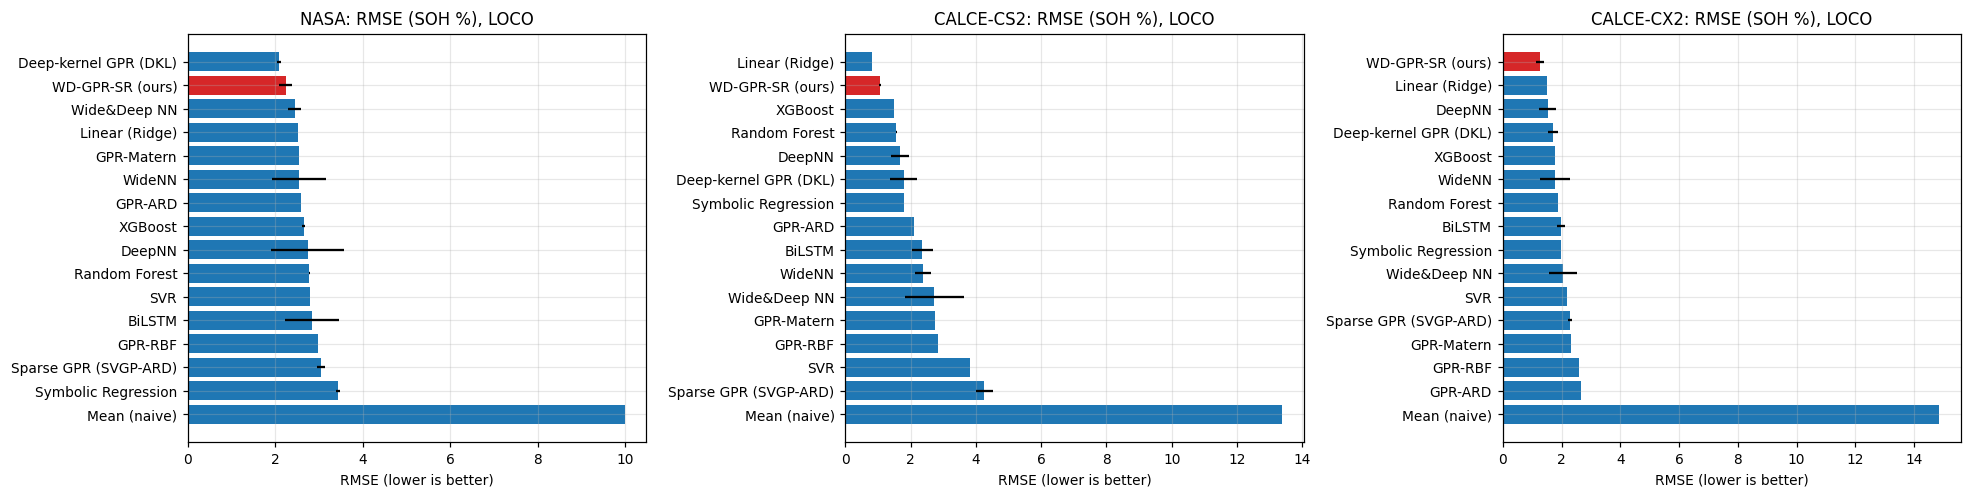


RMSE per unseen test cell (mean over seeds)
test_cell              B0005   B0006  B0007  B0018
model                                             
Mean (naive)           9.472  12.608  9.049  7.803
Linear (Ridge)         1.221   4.524  0.807  1.402
SVR                    0.996   4.632  1.673  2.430
Random Forest          1.946   4.410  1.114  2.452
XGBoost                1.868   4.222  1.318  2.138
GPR-RBF                1.170   4.562  1.046  3.638
GPR-Matern             1.707   3.871  1.391  2.405
GPR-ARD                1.152   4.814  0.874  0.733
Sparse GPR (SVGP-ARD)  1.234   5.513  1.067  1.738
Deep-kernel GPR (DKL)  1.372   3.570  0.998  0.927
WideNN                 0.923   3.492  0.808  3.390
DeepNN                 1.351   3.489  0.849  3.577
Wide&Deep NN           1.495   3.465  1.433  2.726
BiLSTM                 0.727   4.213  0.882  3.692
Symbolic Regression    2.116   4.450  3.185  3.527
WD-GPR-SR (ours)       1.179   3.974  0.810  1.227 

test_cell              CS2_35  CS2_

In [11]:
def per_seed_metrics(P):
    rows = []
    for (d, m, s), g in P.groupby(['dataset', 'model', 'seed'], sort=False):
        sd = g.sd.to_numpy() if g.sd.notna().all() else None
        rows.append(dict(dataset=d, model=m, seed=s, **metrics(g.y.to_numpy(), g.mu.to_numpy(), sd)))
    return pd.DataFrame(rows)


MS = per_seed_metrics(P)
COLS = ['MAE', 'MSE', 'RMSE', 'R2', 'MAPE', 'NLL', 'PICP95', 'MPIW95']
cost = LOG.groupby(['dataset', 'model'])[['train_s', 'size_kb']].mean()
summary = MS.groupby(['dataset', 'model'])[COLS].agg(['mean', 'std'])
summary.to_csv(RES / 'metrics_summary_numeric.csv')


def fmt_table(ds_name, models):
    t = pd.DataFrame(index=models)
    for c in COLS:
        m, s = summary.loc[ds_name][(c, 'mean')], summary.loc[ds_name][(c, 'std')].fillna(0)
        t[c] = [f'{m[k]:.3f} ± {s[k]:.3f}' if pd.notna(m.get(k)) else '-' for k in models]
    t['train_s'] = cost.loc[ds_name].reindex(models)['train_s'].round(2).values
    t['size_kb'] = cost.loc[ds_name].reindex(models)['size_kb'].round(1).values
    return t


TABLES = {}
for ds_name in DATASETS:
    TABLES[ds_name] = fmt_table(ds_name, BASELINES + [OURS])
    TABLES[ds_name].to_csv(RES / f'results_{ds_name}.csv')
    print(f'\n=== {ds_name}: baselines vs proposed (LOCO, mean ± std over {len(SEEDS)} seeds) ===')
    print(TABLES[ds_name].to_string())

fig, axes = plt.subplots(1, len(DATASETS), figsize=(6 * len(DATASETS), 4.6))
for ax, ds_name in zip(axes, DATASETS):
    s = summary.loc[ds_name].reindex(BASELINES + [OURS])
    order = s[('RMSE', 'mean')].sort_values().index
    colors = ['tab:red' if m == OURS else 'tab:blue' for m in order]
    ax.barh(range(len(order)), s.loc[order, ('RMSE', 'mean')], xerr=s.loc[order, ('RMSE', 'std')].fillna(0), color=colors)
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()
    ax.set(title=f'{ds_name}: RMSE (SOH %), LOCO', xlabel='RMSE (lower is better)')
savefig('results_rmse_comparison')

per_cell = P.groupby(['dataset', 'model', 'test_cell', 'seed']).apply(lambda g: np.sqrt(np.mean((g.mu - g.y) ** 2)))
per_cell = per_cell.groupby(['dataset', 'model', 'test_cell']).mean().unstack('test_cell')
per_cell.to_csv(RES / 'per_cell_rmse.csv')
print('\nRMSE per unseen test cell (mean over seeds)')
for ds_name, ds in DATASETS.items():
    print(per_cell.loc[ds_name].reindex(BASELINES + [OURS])[ds['cells']].round(3).to_string(), '\n')

# Wilcoxon signed-rank test on paired (cell, seed) RMSEs: ours against each baseline
pc = P.groupby(['dataset', 'model', 'test_cell', 'seed']).apply(lambda g: np.sqrt(np.mean((g.mu - g.y) ** 2))).rename('rmse').reset_index()
stat_rows = []
for ds_name in DATASETS:
    ours = pc[(pc.dataset == ds_name) & (pc.model == OURS)].set_index(['test_cell', 'seed']).rmse
    for b in BASELINES:
        other = pc[(pc.dataset == ds_name) & (pc.model == b)].set_index(['test_cell', 'seed']).rmse.reindex(ours.index)
        diff = other - ours
        p = wilcoxon(other, ours).pvalue if (diff != 0).any() and len(diff) > 1 else np.nan
        stat_rows.append(dict(dataset=ds_name, baseline=b, n_pairs=len(diff), mean_rmse_gain=diff.mean(), ours_better=int((diff > 0).sum()), p_value=p))
STATS = pd.DataFrame(stat_rows)
STATS.to_csv(RES / 'wilcoxon_vs_baselines.csv', index=False)
print(STATS.round(4).to_string())

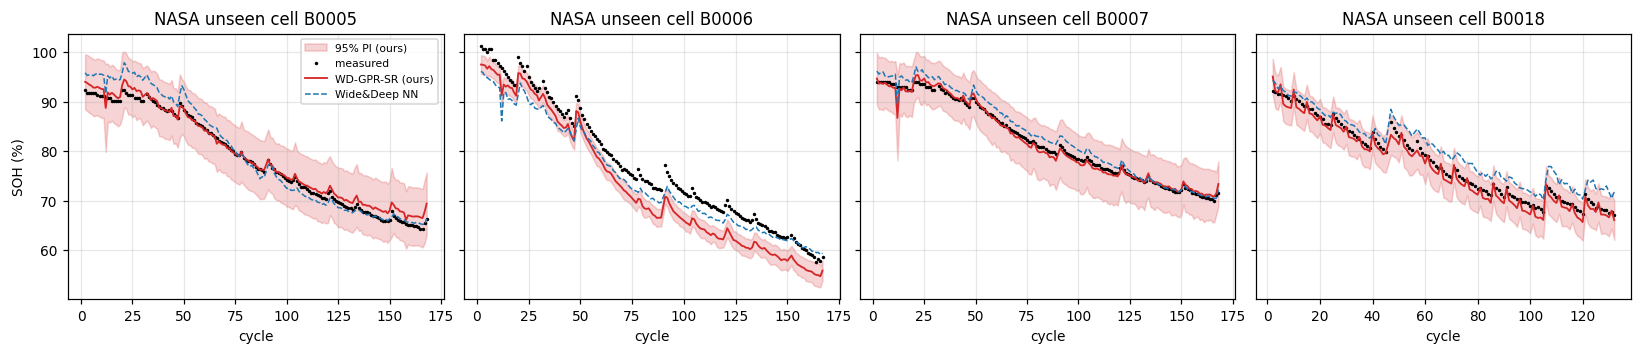

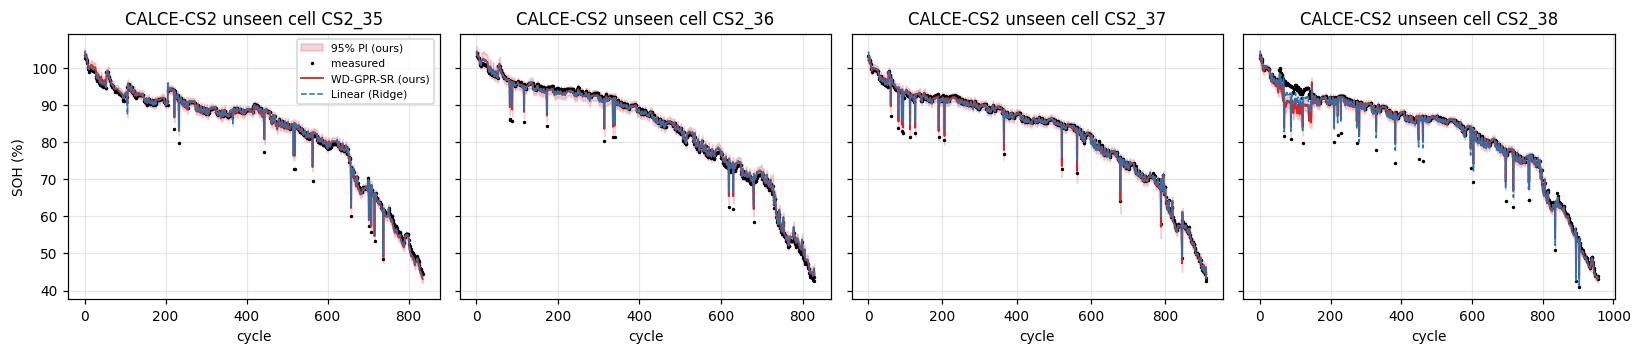

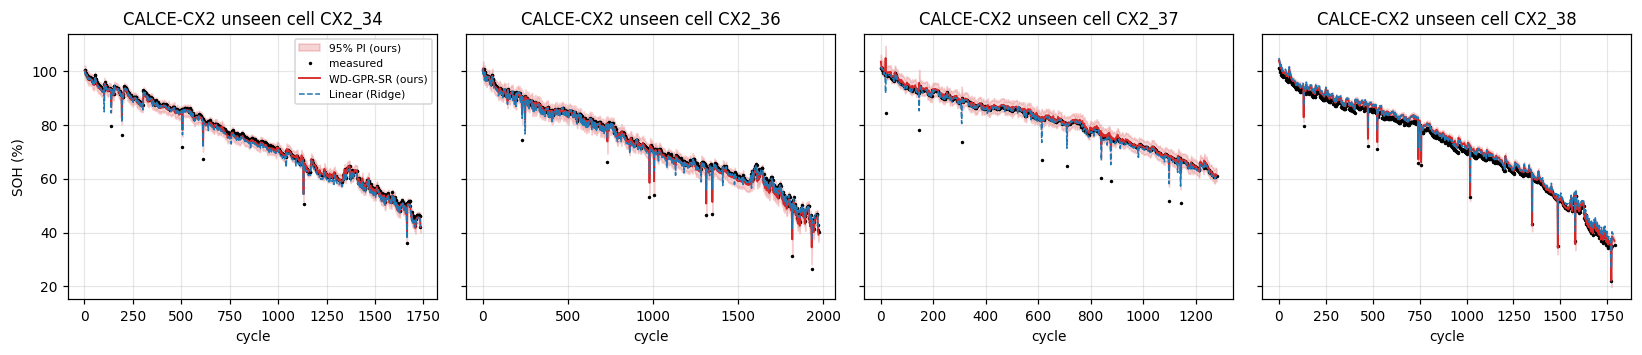

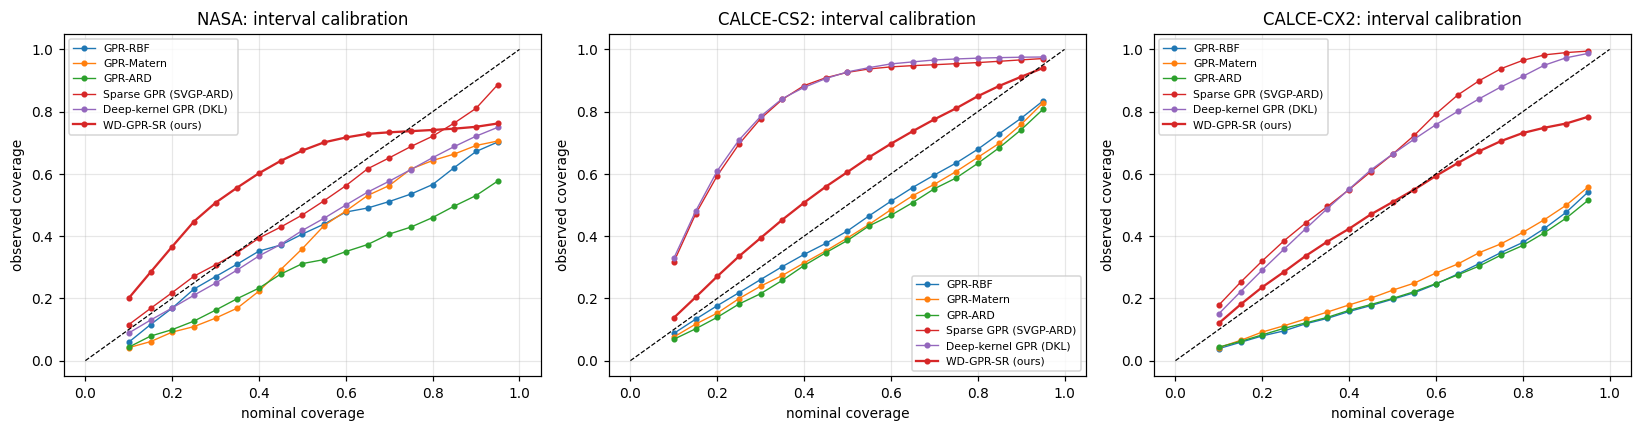

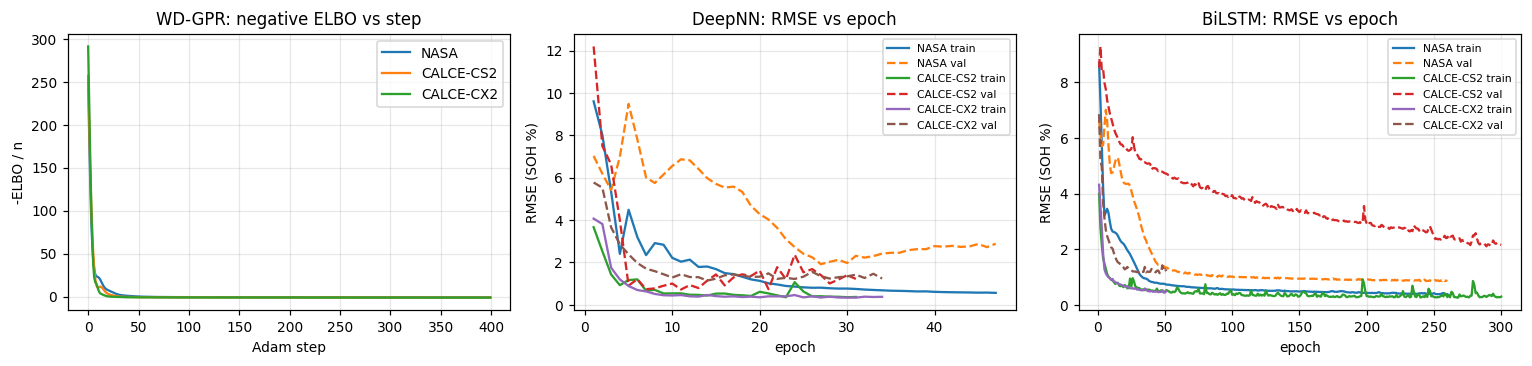


WD-GPR-SR discovered residual equations (z_* = standardised HI, output in SOH %):
      dataset test_cell  seed                     kernel  sigma_scale  nodes  shrinkage                                                                                                                                       raw_equation                         applied_equation
0        NASA     B0005     0                    wide {}     1.977640     21   0.000000                                                                                    3*z_cc_time + 2*z_cv_time + 3*z_ic_peak_v - z_temp_rise + 0.814                                        0
1        NASA     B0005     1                    wide {}     1.897714     15   0.000000                                                                                    2*z_cv_time + z_ic_peak + 2*z_ic_peak_v - 2*z_temp_rise + 0.466                                        0
2        NASA     B0005     2                    wide {}     1.901526     23   0.000000  

In [12]:
# Plot: predicted SOH with its 95 % interval on each unseen cell (seed 0), next to the best non-GP baseline
for ds_name, ds in DATASETS.items():
    best_b = summary.loc[ds_name].reindex([b for b in BASELINES if 'GP' not in b])[('RMSE', 'mean')].idxmin()
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.3), sharey=True)
    for ax, cell in zip(axes, ds['cells']):
        o = P[(P.dataset == ds_name) & (P.test_cell == cell) & (P.seed == SEEDS[0]) & (P.model == OURS)]
        b = P[(P.dataset == ds_name) & (P.test_cell == cell) & (P.seed == SEEDS[0]) & (P.model == best_b)]
        ax.fill_between(o.cycle, o.mu - 1.96 * o.sd, o.mu + 1.96 * o.sd, color='tab:red', alpha=0.2, label='95% PI (ours)')
        ax.plot(o.cycle, o.y, 'k.', ms=2.5, label='measured')
        ax.plot(o.cycle, o.mu, 'tab:red', lw=1.2, label=OURS)
        ax.plot(b.cycle, b.mu, 'tab:blue', lw=1, ls='--', label=best_b)
        ax.set(title=f'{ds_name} unseen cell {cell}', xlabel='cycle')
    axes[0].set_ylabel('SOH (%)')
    axes[0].legend(fontsize=7)
    savefig(f'results_pred_vs_cycle_{ds_name}')

# Calibration plot: how often the true SOH falls inside intervals of each nominal size
from scipy.stats import norm
levels = np.linspace(0.1, 0.95, 18)
prob_models = ['GPR-RBF', 'GPR-Matern', 'GPR-ARD', 'Sparse GPR (SVGP-ARD)', 'Deep-kernel GPR (DKL)', OURS]
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5 * len(DATASETS), 4))
for ax, ds_name in zip(axes, DATASETS):
    for m in prob_models:
        g = P[(P.dataset == ds_name) & (P.model == m)]
        z = np.abs(g.mu - g.y) / g.sd
        ax.plot(levels, [np.mean(z <= norm.ppf(0.5 + a / 2)) for a in levels], marker='.', lw=1.5 if m == OURS else 0.9,
                color='tab:red' if m == OURS else None, label=m)
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
    ax.set(title=f'{ds_name}: interval calibration', xlabel='nominal coverage', ylabel='observed coverage')
    ax.legend(fontsize=7)
savefig('results_calibration')

# Plot: training curves (GP loss, DeepNN and BiLSTM train/val RMSE) for the first test cell, seed 0
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ds_name in DATASETS:
    a = ART[(ds_name, SEEDS[0])]
    axes[0].plot(a['wd'].hist, label=ds_name)
    for ax, nm in zip(axes[1:], ['DeepNN', 'BiLSTM']):
        h = np.array(a[f'{nm}_hist'])
        ax.plot(h[:, 0], h[:, 1], label=f'{ds_name} train')
        ax.plot(h[:, 0], h[:, 2], ls='--', label=f'{ds_name} val')
        ax.set(title=f'{nm}: RMSE vs epoch', xlabel='epoch', ylabel='RMSE (SOH %)')
        ax.legend(fontsize=7)
axes[0].set(title='WD-GPR: negative ELBO vs step', xlabel='Adam step', ylabel='-ELBO / n')
axes[0].legend()
savefig('training_curves')

print('\nWD-GPR-SR discovered residual equations (z_* = standardised HI, output in SOH %):')
print(EQ.to_string())
print('\nEquation complexity (nodes): mean', EQ.nodes.mean().round(2), '| max', EQ.nodes.max())
print('Kernel chosen by inner LOCO (per fold, seed-independent):')
print(EQ[EQ.seed == SEEDS[0]][['dataset', 'test_cell', 'kernel']].to_string(index=False))
print('σ calibration scale s, mean ± std per dataset:', EQ.groupby('dataset').sigma_scale.agg(['mean', 'std']).round(3).to_dict('index'))

## 11. Ablation study
Each variant changes one part of WD-GPR-SR and keeps the data, protocol and seeds the same.


=== NASA: ablation ===
                                                                      change            MAE            MSE           RMSE             R2           MAPE            NLL          PICP95          MPIW95  train_s  size_kb  ΔRMSE vs full
WD-GPR-SR (ours)                                                  full model  1.623 ± 0.077  5.008 ± 0.642  2.235 ± 0.141  0.948 ± 0.007  2.176 ± 0.105  3.896 ± 0.774  76.206 ± 1.976   9.295 ± 0.951    27.27     35.0          0.000
A1: w/o SR correction                                            WD-GPR only  1.623 ± 0.077  5.008 ± 0.642  2.235 ± 0.141  0.948 ± 0.007  2.176 ± 0.105  3.896 ± 0.774  76.206 ± 1.976   9.295 ± 0.951    16.84     31.4          0.000
A2: SR unweighted                                         uniform SR weights  1.651 ± 0.125  5.353 ± 1.238  2.304 ± 0.260  0.945 ± 0.013  2.223 ± 0.185  4.083 ± 1.046  76.527 ± 1.854   9.295 ± 0.951    27.24     35.0          0.069
A3: SR on in-sample residuals                   

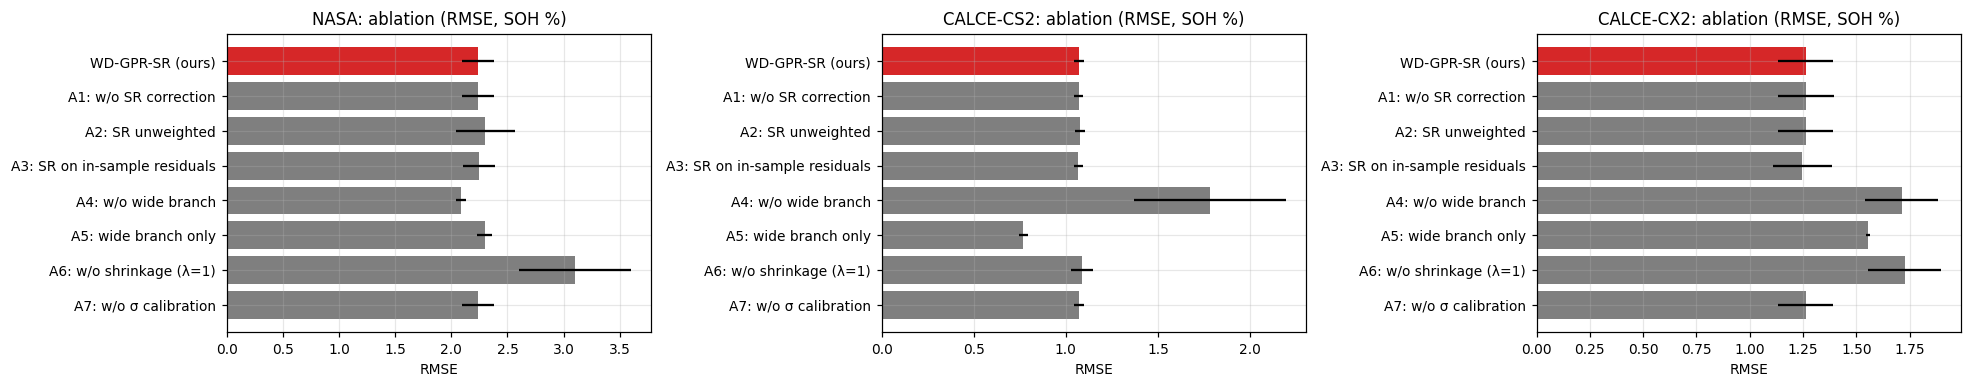

In [13]:
abl_models = [OURS] + list(ABLATIONS)
ABL = {}
for ds_name in DATASETS:
    t = fmt_table(ds_name, abl_models)
    t.insert(0, 'change', ['full model'] + list(ABLATIONS.values()))
    d_rmse = summary.loc[ds_name].reindex(abl_models)[('RMSE', 'mean')]
    t['ΔRMSE vs full'] = (d_rmse - d_rmse[OURS]).round(3).values
    ABL[ds_name] = t
    t.to_csv(RES / f'ablation_{ds_name}.csv')
    print(f'\n=== {ds_name}: ablation ===')
    print(t.to_string())

fig, axes = plt.subplots(1, len(DATASETS), figsize=(6 * len(DATASETS), 3.6))
for ax, ds_name in zip(axes, DATASETS):
    s = summary.loc[ds_name].reindex(abl_models)
    ax.barh(range(len(abl_models)), s[('RMSE', 'mean')], xerr=s[('RMSE', 'std')].fillna(0),
            color=['tab:red'] + ['tab:gray'] * len(ABLATIONS))
    ax.set_yticks(range(len(abl_models)), abl_models)
    ax.invert_yaxis()
    ax.set(title=f'{ds_name}: ablation (RMSE, SOH %)', xlabel='RMSE')
savefig('ablation_rmse')

### Hypothesis check
This checks the hypotheses and the success rule from section 0 directly against the tables above (mean over seeds).

In [14]:
GP_BASE = ['GPR-RBF', 'GPR-Matern', 'GPR-ARD', 'Sparse GPR (SVGP-ARD)', 'Deep-kernel GPR (DKL)']
NON_PROB = ['Linear (Ridge)', 'SVR', 'Random Forest', 'XGBoost', 'WideNN', 'DeepNN', 'Wide&Deep NN', 'BiLSTM', 'Symbolic Regression']
hyp_rows = []
for ds_name in DATASETS:
    m = summary.loc[ds_name]
    rm, rs = m[('RMSE', 'mean')], m[('RMSE', 'std')].fillna(0)
    best_gp = rm[GP_BASE].idxmin()
    best_np = rm[NON_PROB].idxmin()
    picp, mpiw = m.loc[OURS, ('PICP95', 'mean')], m.loc[OURS, ('MPIW95', 'mean')]
    lam = EQ[EQ.dataset == ds_name].shrinkage
    hyp_rows.append(dict(
        dataset=ds_name,
        H1_supported=bool(rm['A1: w/o SR correction'] < rm[best_gp]),
        H1_detail=f"WD-GPR {rm['A1: w/o SR correction']:.3f} vs best GP baseline {best_gp} {rm[best_gp]:.3f}",
        H2_supported=bool(rm[OURS] <= rm['A1: w/o SR correction'] + 1e-9),
        H2_detail=f"with SR {rm[OURS]:.3f} vs without {rm['A1: w/o SR correction']:.3f}; λ>0 in {int((lam > 0).sum())}/{len(lam)} fits; λ=1 gives {rm['A6: w/o shrinkage (λ=1)']:.3f}",
        H3_supported=bool(90 <= picp <= 99),
        H3_detail=f"PICP95 {picp:.1f} %, MPIW95 {mpiw:.2f} SOH %",
        success=bool(rm[OURS] <= rm[GP_BASE].min() and rm[OURS] <= rm[best_np] + rs[best_np] and 90 <= picp <= 99),
        success_detail=f"ours {rm[OURS]:.3f}±{rs[OURS]:.3f}; best non-probabilistic {best_np} {rm[best_np]:.3f}±{rs[best_np]:.3f}"))
HYP = pd.DataFrame(hyp_rows)
HYP.to_csv(RES / 'hypothesis_check.csv', index=False)
for r in hyp_rows:
    print(f"\n{r['dataset']}:")
    for h in ['H1', 'H2', 'H3', 'success']:
        print(f"  {h:8s} {'SUPPORTED' if r[h + ('_supported' if h != 'success' else '')] else 'NOT SUPPORTED':14s} {r[h + '_detail']}")


NASA:
  H1       NOT SUPPORTED  WD-GPR 2.235 vs best GP baseline Deep-kernel GPR (DKL) 2.086
  H2       SUPPORTED      with SR 2.235 vs without 2.235; λ>0 in 0/12 fits; λ=1 gives 3.102
  H3       NOT SUPPORTED  PICP95 76.2 %, MPIW95 9.30 SOH %
  success  NOT SUPPORTED  ours 2.235±0.141; best non-probabilistic Wide&Deep NN 2.440±0.143

CALCE-CS2:
  H1       SUPPORTED      WD-GPR 1.069 vs best GP baseline Deep-kernel GPR (DKL) 1.783
  H2       NOT SUPPORTED  with SR 1.072 vs without 1.069; λ>0 in 1/12 fits; λ=1 gives 1.089
  H3       SUPPORTED      PICP95 94.0 %, MPIW95 2.39 SOH %
  success  NOT SUPPORTED  ours 1.072±0.026; best non-probabilistic Linear (Ridge) 0.827±0.000

CALCE-CX2:
  H1       SUPPORTED      WD-GPR 1.266 vs best GP baseline Deep-kernel GPR (DKL) 1.713
  H2       SUPPORTED      with SR 1.262 vs without 1.266; λ>0 in 1/12 fits; λ=1 gives 1.727
  H3       NOT SUPPORTED  PICP95 78.3 %, MPIW95 4.25 SOH %
  success  NOT SUPPORTED  ours 1.262±0.128; best non-probabilistic Li

## 12. Explainability (XAI)
I explain the final WD-GPR-SR pipeline (GP mean plus symbolic correction) on the first LOCO fold of each dataset (test cells B0005, CS2_35 and CX2_34), seed 0, with seven methods: SHAP (KernelExplainer), LIME, partial dependence (PDP), individual conditional expectation (ICE), ARD relevance, the symbolic sensitivities ∂g/∂x, and permutation importance.

The main HIs are almost collinear (|ρ| ≈ 0.97), so the ARD-linear weights of the wide branch are hard to pin down: the marginal likelihood hardly changes when weight moves from one correlated HI to another. SHAP, LIME, PDP and permutation importance look at the predictions themselves, so I trust them more here. To check agreement, I compute the Spearman rank correlation between the importance rankings of the methods, and between the SHAP rankings of the 3 seeds. These attributions describe the model, not cause and effect inside the cell.

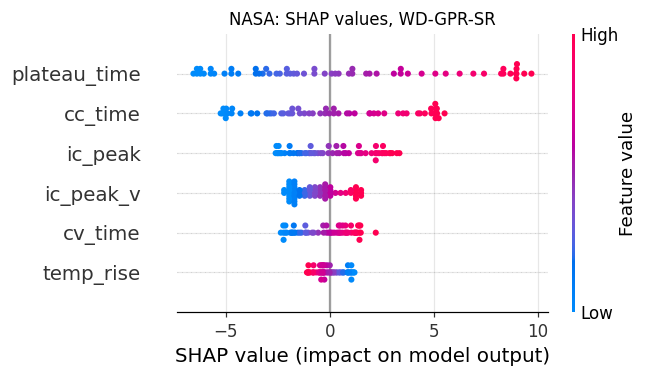

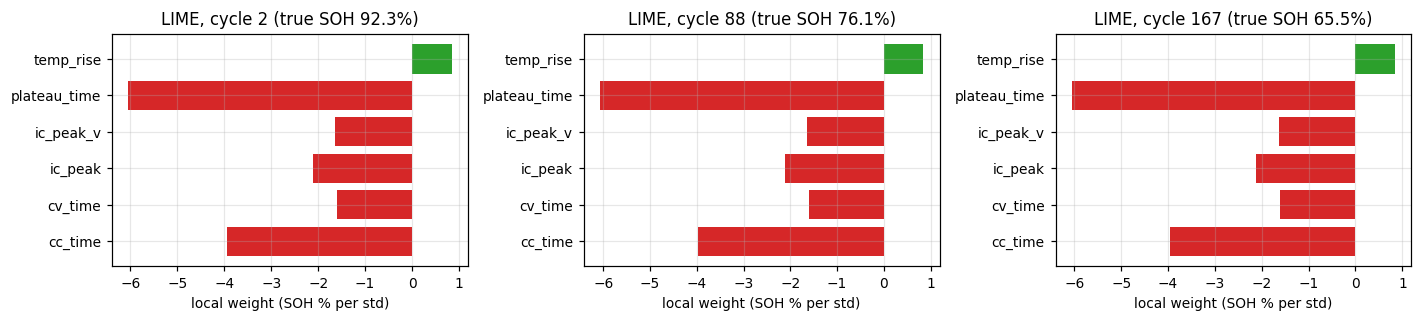

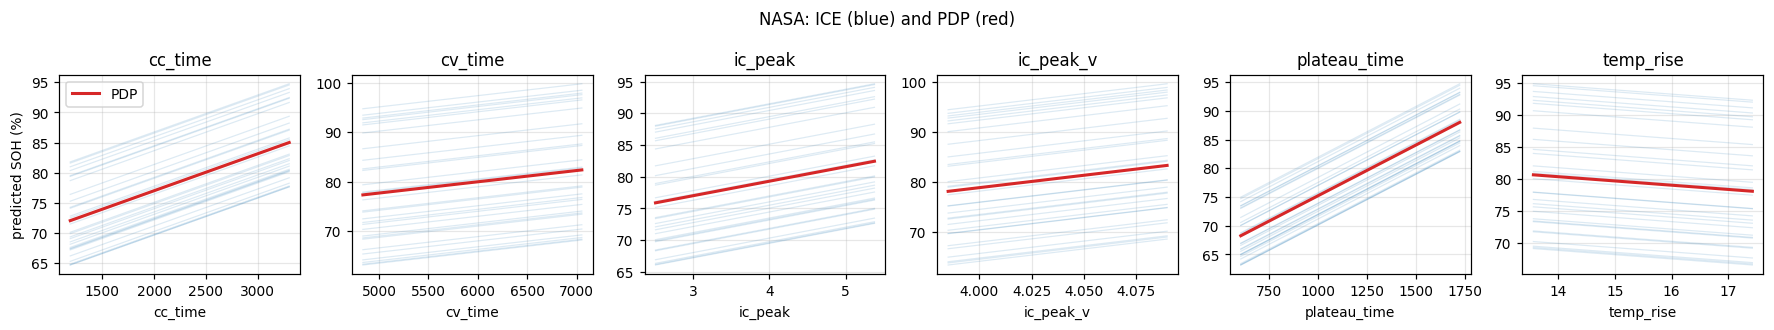

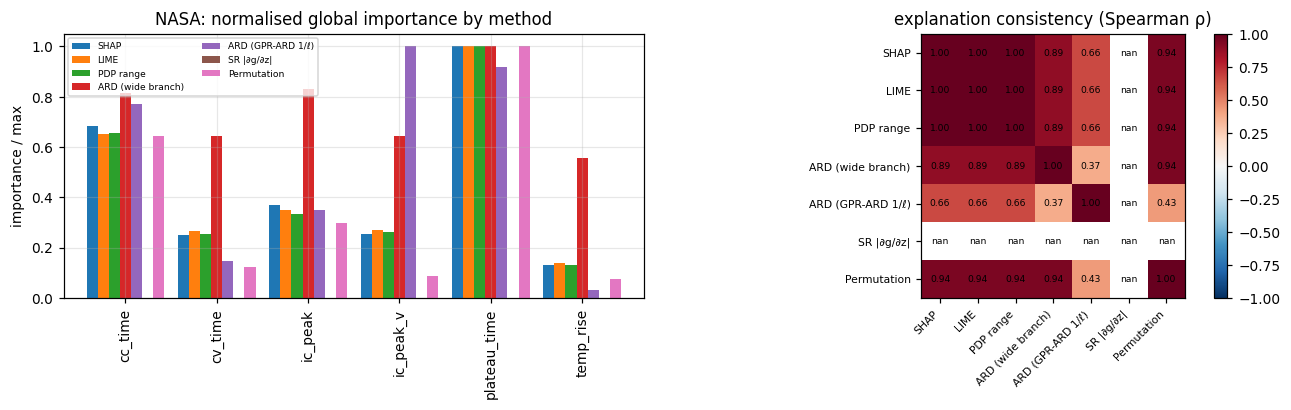


NASA: global importance
                SHAP    LIME  PDP range  ARD (wide branch)  ARD (GPR-ARD 1/ℓ)  SR |∂g/∂z|  Permutation
cc_time       3.0525  3.9592    12.9813             0.3673             0.8428         0.0       4.3513
cv_time       1.1221  1.6059     5.0516             0.2907             0.1621         0.0       0.8422
ic_peak       1.6515  2.1212     6.5627             0.3735             0.3807         0.0       2.0290
ic_peak_v     1.1288  1.6368     5.1792             0.2901             1.0926         0.0       0.5844
plateau_time  4.4572  6.0584    19.7562             0.4501             1.0013         0.0       6.7763
temp_rise     0.5877  0.8451     2.5658             0.2501             0.0364         0.0       0.5191
NASA: mean pairwise Spearman between XAI methods = 0.813; SHAP ranking stability across seeds = 0.962
NASA: residual equation g(z) = 0


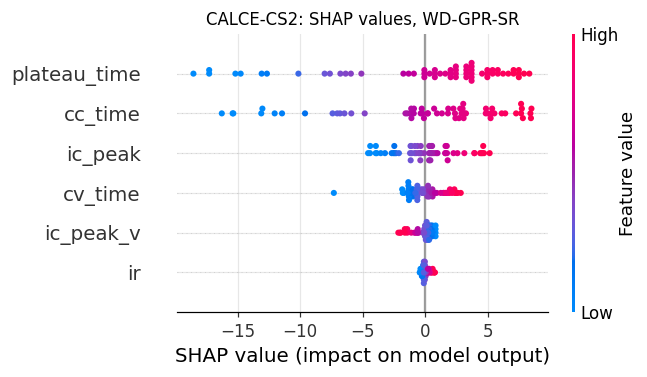

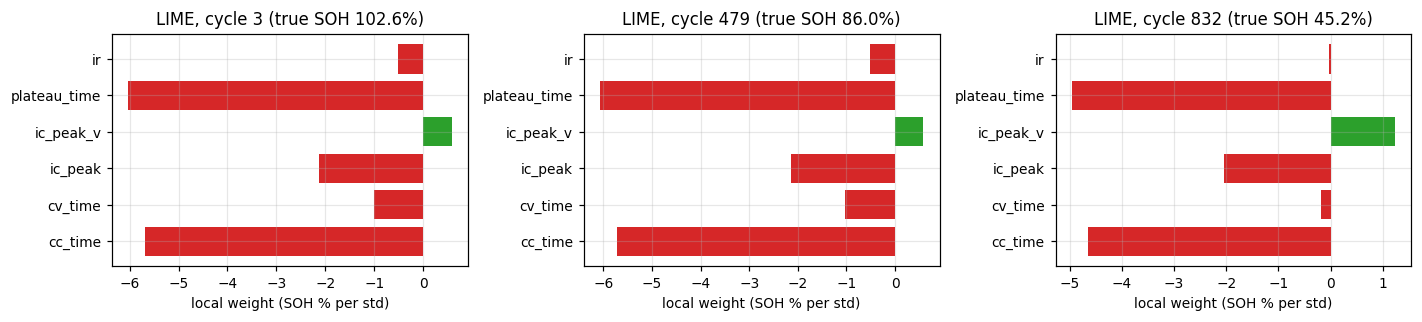

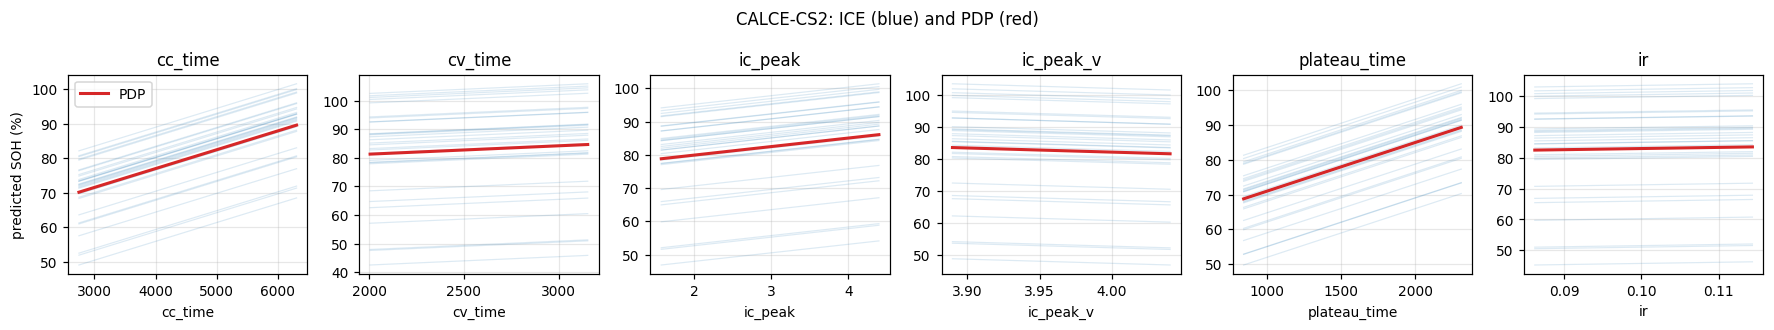

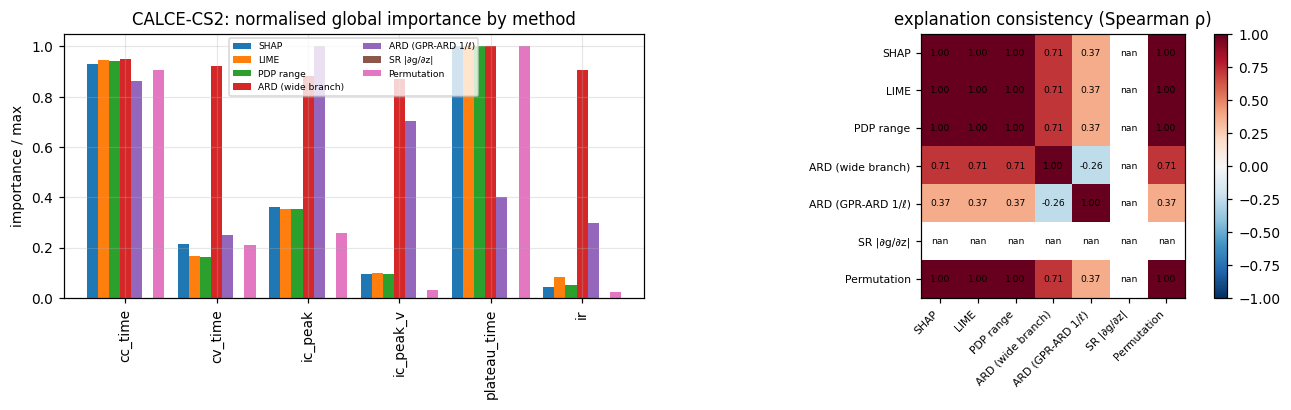


CALCE-CS2: global importance
                SHAP    LIME  PDP range  ARD (wide branch)  ARD (GPR-ARD 1/ℓ)  SR |∂g/∂z|  Permutation
cc_time       5.0686  5.6753    19.3802             0.3488             0.8797         0.0       7.3239
cv_time       1.1760  0.9942     3.3556             0.3385             0.2556         0.0       1.7076
ic_peak       1.9727  2.1297     7.2379             0.3236             1.0211         0.0       2.1002
ic_peak_v     0.5241  0.5984     1.9405             0.3196             0.7203         0.0       0.2412
plateau_time  5.4527  6.0112    20.5667             0.3668             0.4081         0.0       8.0842
ir            0.2279  0.5049     1.0340             0.3320             0.3023         0.0       0.2006
CALCE-CS2: mean pairwise Spearman between XAI methods = 0.672; SHAP ranking stability across seeds = 0.924
CALCE-CS2: residual equation g(z) = 0


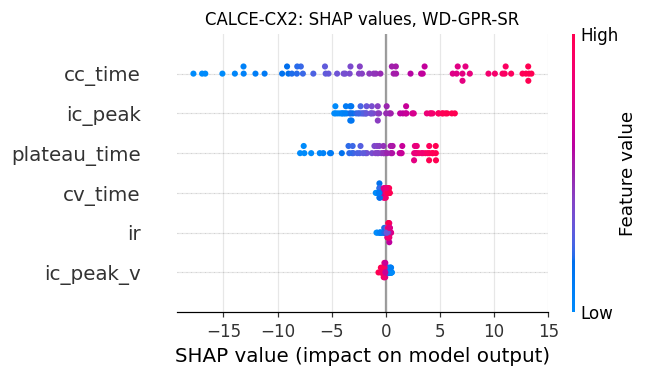

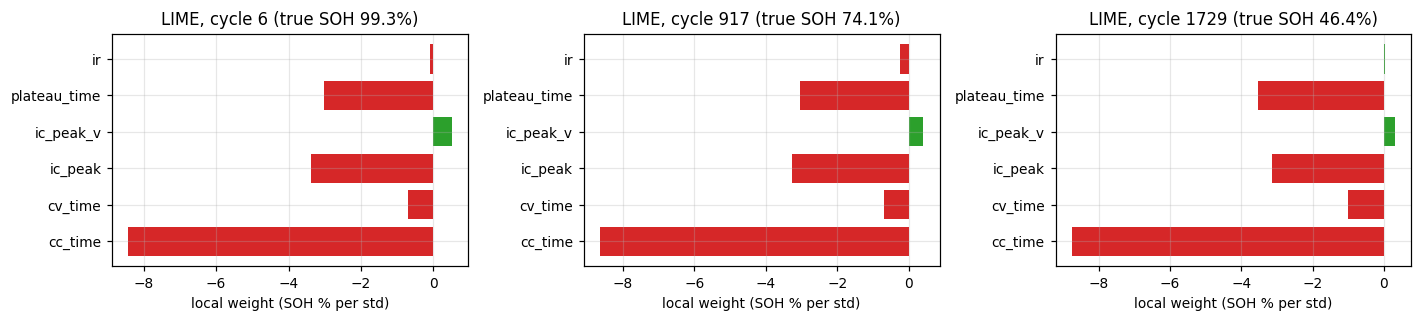

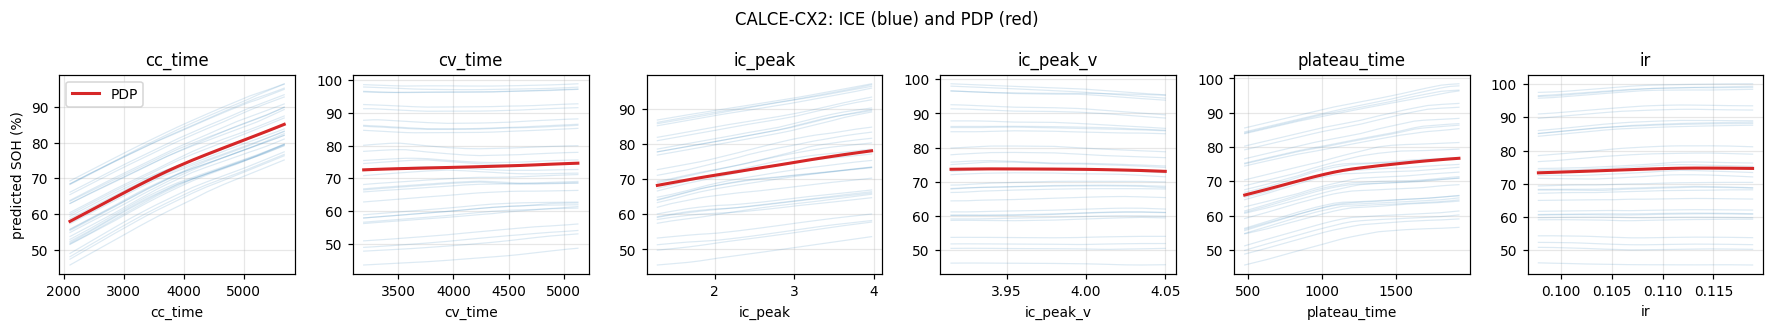

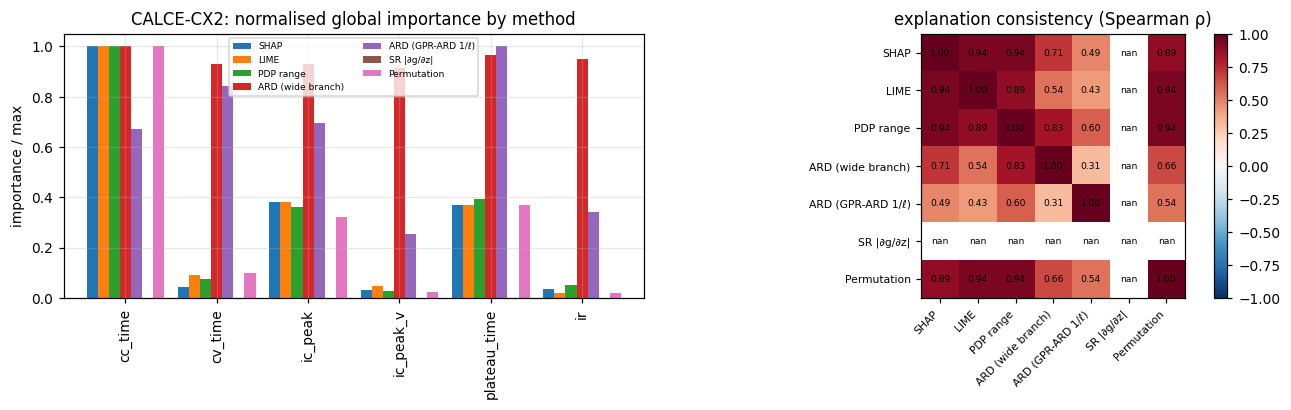


CALCE-CX2: global importance
                SHAP    LIME  PDP range  ARD (wide branch)  ARD (GPR-ARD 1/ℓ)  SR |∂g/∂z|  Permutation
cc_time       7.6344  8.5299    27.1950             0.4230             0.8600         0.0      11.0310
cv_time       0.3234  0.7620     2.0387             0.3938             1.0773         0.0       1.1054
ic_peak       2.9144  3.2633     9.8393             0.3941             0.8893         0.0       3.5476
ic_peak_v     0.2503  0.3996     0.7215             0.3870             0.3255         0.0       0.2508
plateau_time  2.8090  3.1393    10.7042             0.4084             1.2813         0.0       4.0775
ir            0.2717  0.1750     1.4252             0.4022             0.4390         0.0       0.2083
CALCE-CX2: mean pairwise Spearman between XAI methods = 0.710; SHAP ranking stability across seeds = 0.905
CALCE-CX2: residual equation g(z) = 0


In [15]:
def ours_fn(a):
    return lambda X: wd_predict(a['wd'], a['sr'], np.asarray(X, float))[0]


XAI = {}
for ds_name, ds in DATASETS.items():
    F, a = ds['feats'], ART[(ds_name, SEEDS[0])]
    f, fn = a['f'], ours_fn(a)
    Xtr, Xte, yte = f['Xtr'], f['Xte'], f['yte']
    rng = np.random.default_rng(0)
    idx = np.sort(rng.choice(len(Xte), size=min(60, len(Xte)), replace=False))
    bg = shap.kmeans(Xtr, 10)
    imp = {}

    def shap_for(func):
        ex = shap.KernelExplainer(func, bg)
        return ex.shap_values(Xte[idx], nsamples=200, silent=True)

    sv = shap_for(fn)
    imp['SHAP'] = np.abs(sv).mean(0)
    plt.figure()
    shap.summary_plot(sv, Xte[idx], feature_names=F, show=False, plot_size=(6, 3.5))
    plt.title(f'{ds_name}: SHAP values, WD-GPR-SR')
    savefig(f'xai_shap_{ds_name}')

    lime_ex = LimeTabularExplainer(Xtr, feature_names=F, mode='regression', random_state=0, discretize_continuous=False)
    lw = []
    for k in idx[::2]:
        e = lime_ex.explain_instance(Xte[k], fn, num_features=len(F), num_samples=1000)
        w = dict(next(iter(e.as_map().values())))
        lw.append([w.get(j, 0.0) for j in range(len(F))])
    lw = np.array(lw)
    imp['LIME'] = np.abs(lw).mean(0)
    picks = [idx[0], idx[len(idx) // 2], idx[-1]]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    for ax, k in zip(axes, picks):
        w = dict(next(iter(lime_ex.explain_instance(Xte[k], fn, num_features=len(F), num_samples=1000).as_map().values())))
        vals = [w.get(j, 0.0) for j in range(len(F))]
        ax.barh(F, vals, color=['tab:green' if v > 0 else 'tab:red' for v in vals])
        ax.set(title=f'LIME, cycle {f["cyc"][k]} (true SOH {yte[k]:.1f}%)', xlabel='local weight (SOH % per std)')
    savefig(f'xai_lime_{ds_name}')

    fig, axes = plt.subplots(1, len(F), figsize=(2.7 * len(F), 3))
    ice_idx = idx[::max(1, len(idx) // 30)]
    pdp_range = []
    for j, (ax, name) in enumerate(zip(axes, F)):
        grid = np.quantile(Xtr[:, j], np.linspace(0.05, 0.95, 20))
        curves = []
        for gv in grid:
            Xg = Xte[ice_idx].copy()
            Xg[:, j] = gv
            curves.append(fn(Xg))
        curves = np.array(curves).T
        ax.plot(grid, curves.T, color='tab:blue', alpha=0.15, lw=0.8)
        ax.plot(grid, curves.mean(0), color='tab:red', lw=2, label='PDP')
        pdp_range.append(np.ptp(curves.mean(0)))
        ax.set(title=name, xlabel=name, ylabel='predicted SOH (%)' if j == 0 else '')
    axes[0].legend()
    fig.suptitle(f'{ds_name}: ICE (blue) and PDP (red)')
    savefig(f'xai_pdp_ice_{ds_name}')
    imp['PDP range'] = np.array(pdp_range)

    km = a['wd'].gp.covar_module
    wide_w = (km if a['wd'].kind == 'wide' else km.kernels[0]).weight.detach().numpy()
    ls = a['GPR-ARD']['m'].kernel_.k1.k2.length_scale
    imp['ARD (wide branch)'] = wide_w
    imp['ARD (GPR-ARD 1/ℓ)'] = 1.0 / np.asarray(ls)

    expr = a['expr']
    zte = a['wd'].sc.transform(Xte)
    sens = []
    for j, name in enumerate(F):
        s = sp.Symbol(f'z_{name}')
        dfun = sp.lambdify([sp.Symbol(f'z_{n}') for n in F], sp.diff(expr, s), 'numpy')
        sens.append(float(np.mean(np.abs(np.broadcast_to(dfun(*zte.T), (len(zte),))))))
    imp['SR |∂g/∂z|'] = np.array(sens)

    base = np.sqrt(np.mean((fn(Xte) - yte) ** 2))
    perm = []
    for j in range(len(F)):
        inc = []
        for r in range(5):
            Xp = Xte.copy()
            Xp[:, j] = np.random.default_rng(r).permutation(Xp[:, j])
            inc.append(np.sqrt(np.mean((fn(Xp) - yte) ** 2)) - base)
        perm.append(np.mean(inc))
    imp['Permutation'] = np.array(perm)

    seed_rank = [imp['SHAP']]
    for s in SEEDS[1:]:
        seed_rank.append(np.abs(shap_for(ours_fn(ART[(ds_name, s)]))).mean(0))
    IMP = pd.DataFrame(imp, index=F)
    XAI[ds_name] = dict(imp=IMP, seed_shap=np.array(seed_rank), expr=expr)
    IMP.to_csv(RES / f'xai_importance_{ds_name}.csv')

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    (IMP / IMP.abs().max()).plot.bar(ax=axes[0], width=0.85)
    axes[0].set(title=f'{ds_name}: normalised global importance by method', ylabel='importance / max')
    axes[0].legend(fontsize=6, ncol=2)
    cons = IMP.corr(method='spearman')
    im = axes[1].imshow(cons, vmin=-1, vmax=1, cmap='RdBu_r')
    axes[1].set_xticks(range(len(cons)), cons.columns, rotation=45, ha='right', fontsize=7)
    axes[1].set_yticks(range(len(cons)), cons.columns, fontsize=7)
    for p_ in range(len(cons)):
        for q_ in range(len(cons)):
            axes[1].text(q_, p_, f'{cons.iloc[p_, q_]:.2f}', ha='center', va='center', fontsize=6)
    axes[1].set_title('explanation consistency (Spearman ρ)')
    axes[1].grid(False)
    plt.colorbar(im, ax=axes[1])
    savefig(f'xai_consistency_{ds_name}')
    cons.to_csv(RES / f'xai_consistency_{ds_name}.csv')

    off = cons.values[np.triu_indices(len(cons), 1)]
    sr_seeds = [spearmanr(XAI[ds_name]['seed_shap'][i], XAI[ds_name]['seed_shap'][k])[0]
                for i in range(len(SEEDS)) for k in range(i + 1, len(SEEDS))]
    print(f'\n{ds_name}: global importance\n{IMP.round(4).to_string()}')
    print(f'{ds_name}: mean pairwise Spearman between XAI methods = {np.nanmean(off):.3f}; '
          f'SHAP ranking stability across seeds = {np.nanmean(sr_seeds) if sr_seeds else float("nan"):.3f}')
    print(f'{ds_name}: residual equation g(z) = {show_expr(expr)}')

## 13. Error analysis
Here the errors are split by true-SOH range and by cell, and the worst predictions are listed, to see where the model goes wrong and not just its average error.


NASA: MAE by SOH range (counts {'<75': 777, '75-80': 273, '80-85': 219, '85-90': 222, '90-95': 315, '>95': 60})
model    WD-GPR-SR (ours)  A1: w/o SR correction  Deep-kernel GPR (DKL)  GPR-ARD  XGBoost  BiLSTM
soh_bin                                                                                          
<75                 2.253                  2.253                  1.751    2.482    2.660   2.068
75-80               1.215                  1.215                  1.229    1.043    1.816   2.381
80-85               0.985                  0.985                  0.929    0.740    1.103   2.135
85-90               0.856                  0.856                  1.069    0.845    1.374   1.380
90-95               1.155                  1.155                  1.492    1.132    1.570   1.138
>95                 2.950                  2.950                  3.377    3.820    4.386   4.119

CALCE-CS2: MAE by SOH range (counts {'<75': 2421, '75-80': 990, '80-85': 1023, '85-90': 2364, '90-95':

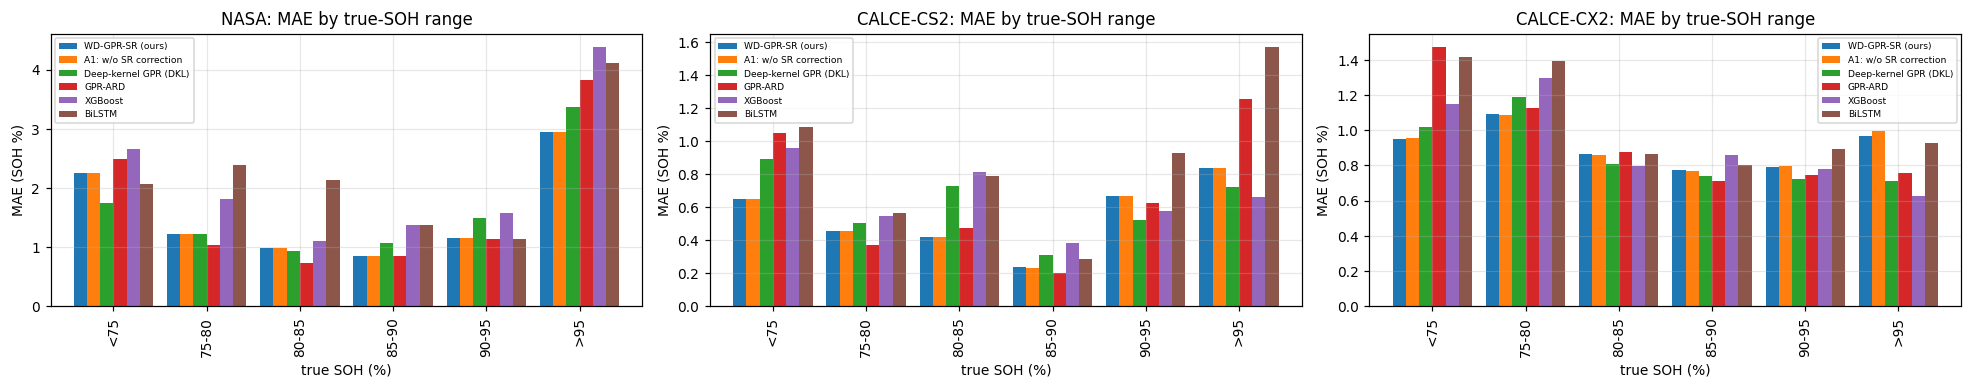

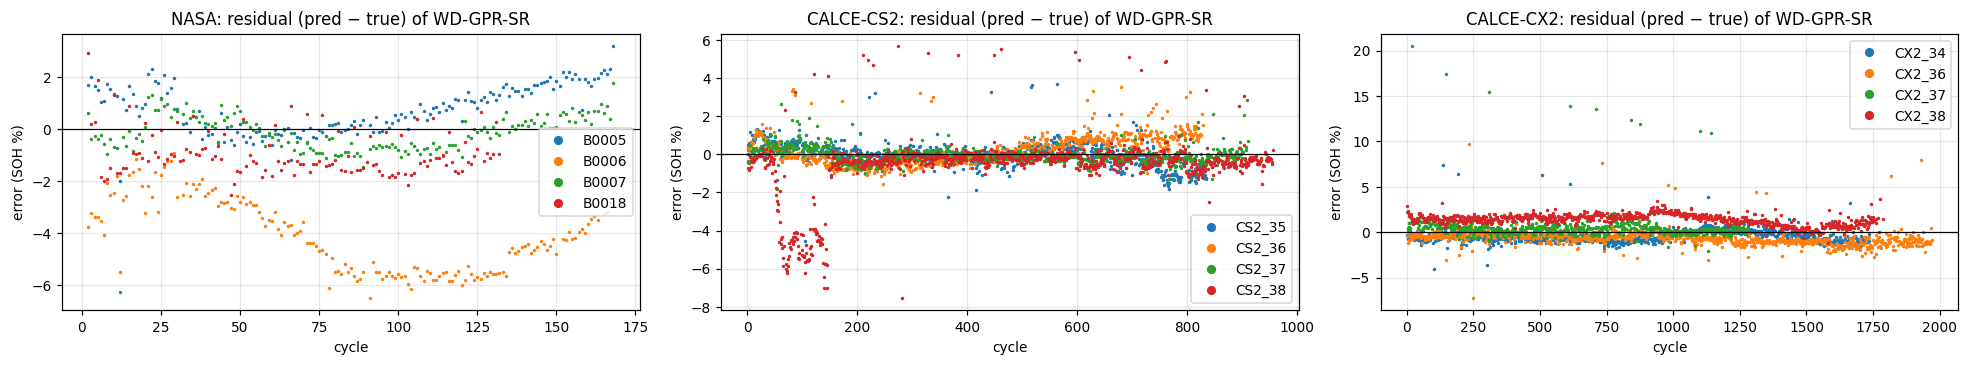


Worst WD-GPR-SR predictions (all seeds):
  dataset test_cell  seed  cycle      y      mu    sd    err
CALCE-CX2    CX2_37     0     19 84.306 104.765 2.289 20.459
CALCE-CX2    CX2_37     0    147 78.151  95.590 2.470 17.439
CALCE-CX2    CX2_37     0    309 73.694  89.156 2.566 15.461
CALCE-CX2    CX2_37     0    614 67.039  80.970 2.515 13.931
CALCE-CX2    CX2_37     0    710 64.814  78.406 2.414 13.592
CALCE-CS2    CS2_38     1    145 92.312  82.405 1.154 -9.907
CALCE-CS2    CS2_38     2    281 89.896  80.728 0.644 -9.168
CALCE-CS2    CS2_38     2    461 74.828  83.202 4.026  8.374
CALCE-CS2    CS2_38     2    695 64.168  72.462 4.281  8.294
CALCE-CS2    CS2_38     2    274 79.801  88.046 3.790  8.245
     NASA     B0006     0     91 77.320  70.849 0.762 -6.471
     NASA     B0007     1     12 92.983  86.536 4.547 -6.447
     NASA     B0007     0     12 92.983  86.734 4.392 -6.249
     NASA     B0006     0    104 72.613  66.480 0.861 -6.133
     NASA     B0006     0     78 76.514  70

In [16]:
key_models = [OURS, 'A1: w/o SR correction', 'Deep-kernel GPR (DKL)', 'GPR-ARD', 'XGBoost', 'BiLSTM']
bins = [0, 75, 80, 85, 90, 95, 200]
labels = ['<75', '75-80', '80-85', '85-90', '90-95', '>95']
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6 * len(DATASETS), 3.6))
ERR = {}
for ax, ds_name in zip(axes, DATASETS):
    g = P[(P.dataset == ds_name) & P.model.isin(key_models)].copy()
    g['abs_err'] = (g.mu - g.y).abs()
    g['soh_bin'] = pd.cut(g.y, bins, labels=labels)
    t = g.groupby(['soh_bin', 'model'], observed=True).abs_err.mean().unstack('model')[key_models]
    ERR[ds_name] = t
    t.plot.bar(ax=ax, width=0.85)
    ax.set(title=f'{ds_name}: MAE by true-SOH range', xlabel='true SOH (%)', ylabel='MAE (SOH %)')
    ax.legend(fontsize=6)
    print(f'\n{ds_name}: MAE by SOH range (counts {g[g.model == OURS].soh_bin.value_counts().sort_index().to_dict()})')
    print(t.round(3).to_string())
savefig('error_by_soh_range')

fig, axes = plt.subplots(1, len(DATASETS), figsize=(6 * len(DATASETS), 3.4))
for ax, (ds_name, ds) in zip(axes, DATASETS.items()):
    g = P[(P.dataset == ds_name) & (P.model == OURS) & (P.seed == SEEDS[0])]
    for c, gc in g.groupby('test_cell'):
        ax.plot(gc.cycle, gc.mu - gc.y, '.', ms=2.5, label=c)
    ax.axhline(0, color='k', lw=0.8)
    ax.set(title=f'{ds_name}: residual (pred − true) of WD-GPR-SR', xlabel='cycle', ylabel='error (SOH %)')
    ax.legend(markerscale=4)
savefig('error_residual_vs_cycle')

worst = P[P.model == OURS].assign(err=lambda d: d.mu - d.y, abs_err=lambda d: (d.mu - d.y).abs())
worst = worst.sort_values('abs_err', ascending=False).groupby('dataset').head(5)
print('\nWorst WD-GPR-SR predictions (all seeds):')
print(worst[['dataset', 'test_cell', 'seed', 'cycle', 'y', 'mu', 'sd', 'err']].round(3).to_string(index=False))
z = (worst.err / worst.sd).abs()
print('|error| / predicted std for these points:', z.round(2).tolist())

### 13b. Robustness to sensor noise
I add Gaussian noise to each health indicator of the unseen test cell. The noise has standard deviation $k\cdot s_j$, where $s_j$ is that HI's standard deviation in the training cells and $k\in\{0, 0.05, 0.1, 0.2, 0.3\}$. Every model gets the same 5 noise draws per level. I reuse the models already trained on the first LOCO fold (seed 0), so nothing is retrained. Leave-one-cell-out already tests a new battery; this adds measurement noise on top.

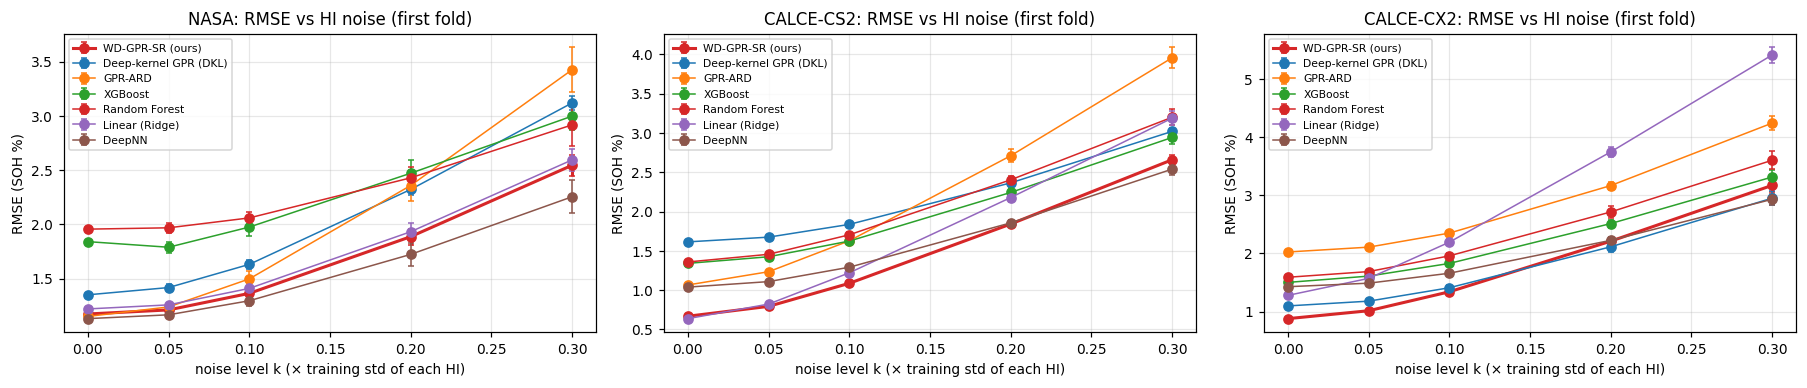

noise_k                           0.00   0.05   0.10   0.20   0.30
dataset   model                                                   
CALCE-CS2 Deep-kernel GPR (DKL)  1.614  1.674  1.836  2.364  3.019
          DeepNN                 1.038  1.108  1.291  1.856  2.539
          GPR-ARD                1.065  1.234  1.627  2.709  3.956
          Linear (Ridge)         0.637  0.822  1.220  2.177  3.187
          Random Forest          1.358  1.455  1.704  2.403  3.199
          WD-GPR-SR (ours)       0.667  0.793  1.086  1.840  2.658
          XGBoost                1.340  1.424  1.624  2.243  2.942
CALCE-CX2 Deep-kernel GPR (DKL)  1.098  1.180  1.411  2.115  2.952
          DeepNN                 1.428  1.489  1.660  2.226  2.932
          GPR-ARD                2.026  2.109  2.351  3.169  4.243
          Linear (Ridge)         1.279  1.572  2.195  3.748  5.415
          Random Forest          1.591  1.689  1.959  2.715  3.604
          WD-GPR-SR (ours)       0.879  1.015  1.341  2.212  3

In [17]:
NOISE_LEVELS = [0.0, 0.05, 0.1, 0.2, 0.3]
rob_rows = []
for ds_name in DATASETS:
    a = ART[(ds_name, SEEDS[0])]
    f = a['f']
    s_j = f['Xtr'].std(0)
    fns = {OURS: ours_fn(a), 'Deep-kernel GPR (DKL)': lambda X, g=a['dkl']: gp_predict(g, X)[0],
           'GPR-ARD': a['GPR-ARD'].predict, 'XGBoost': a['XGBoost'].predict, 'Random Forest': a['Random Forest'].predict,
           'Linear (Ridge)': a['Linear (Ridge)'].predict, 'DeepNN': lambda X, m=a['DeepNN']: nn_predict(m, m.sc.transform(X))}
    for k in NOISE_LEVELS:
        for r in range(5):
            Xn = f['Xte'] + np.random.default_rng(1000 + r).normal(size=f['Xte'].shape) * k * s_j
            for name, fn in fns.items():
                rob_rows.append(dict(dataset=ds_name, noise_k=k, rep=r, model=name, rmse=float(np.sqrt(np.mean((fn(Xn) - f['yte']) ** 2)))))
ROB = pd.DataFrame(rob_rows)
rob_tab = ROB.groupby(['dataset', 'model', 'noise_k']).rmse.agg(['mean', 'std']).round(3)
rob_tab.to_csv(RES / 'robustness_noise.csv')
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.5 * len(DATASETS), 3.6))
for ax, ds_name in zip(axes, DATASETS):
    for name, g in ROB[ROB.dataset == ds_name].groupby('model', sort=False):
        m = g.groupby('noise_k').rmse.agg(['mean', 'std'])
        ax.errorbar(m.index, m['mean'], yerr=m['std'], marker='o', capsize=2, lw=2 if name == OURS else 1,
                    color='tab:red' if name == OURS else None, label=name)
    ax.set(title=f'{ds_name}: RMSE vs HI noise (first fold)', xlabel='noise level k (× training std of each HI)', ylabel='RMSE (SOH %)')
    ax.legend(fontsize=7)
savefig('robustness_noise')
print(rob_tab.unstack('noise_k')['mean'].to_string())

## 14. Edge deployment: export and benchmark
The problem statement asks for a model that can run on a Jetson Orin Nano. I export the trained WD-GPR-SR (NASA, first fold, seed 0) as:
* plain arrays (`.npz`): the MLP feature-extractor weights (only if the Wide-and-Deep kernel was chosen), the inducing points $Z$, the variational parameters $(m,S)$, the kernel hyperparameters, the σ calibration scale and the scalers;
* the symbolic correction $g^*$ as a C function (`.c`).

A NumPy-only predictor rebuilds the model from these arrays, and its output is checked against the PyTorch/gpytorch model (assert tolerance 1e-8; the measured difference is printed below).

**I did not have a Jetson Orin Nano.** The latency and memory numbers below are from the CPU that ran this notebook (shown under the table), not from a Jetson, and energy per prediction cannot be measured here. Latency is the median and 95th percentile of 1,000 single-sample runs after 50 warm-up runs. Memory is the peak Python-heap allocation during one prediction (tracemalloc), so native PyTorch/XGBoost buffers are not counted.

In [18]:
class EdgeWDGPRSR:
    """Runs the exported WD-GPR-SR with NumPy only (no PyTorch or gpytorch needed)."""

    def __init__(self, arr, expr, feats):
        self.a = dict(arr)
        self.has_phi = 'W0' in self.a
        a = self.a
        Z = a['Z']
        Kzz = self.k(Z, Z) + a['jitter'] * np.eye(len(Z))
        L = np.linalg.cholesky(Kzz)
        Linv = scipy.linalg.solve_triangular(L, np.eye(len(Z)), lower=True)
        self.A = Linv.T @ a['m']
        self.B = Linv.T @ (a['S'] - np.eye(len(Z))) @ Linv
        self.g = sp.lambdify([sp.Symbol(f'z_{n}') for n in feats], expr, 'numpy')

    @classmethod
    def export(cls, gp, expr, feats, sig_scale):
        vs = gp.gp.variational_strategy
        q = vs.variational_distribution
        t = lambda x: x.detach().numpy().astype(np.float64)
        arr = dict(x_mean=gp.sc.mean_, x_scale=gp.sc.scale_, y_mean=np.array(gp.ym), y_std=np.array(gp.ys),
                   Z=t(vs.inducing_points), m=t(q.mean), S=t(q.covariance_matrix), c=np.array(float(gp.gp.mean_module.constant)),
                   noise=t(gp.lik.noise).ravel(), sig_scale=np.array(sig_scale),
                   jitter=np.array(gpytorch.settings.variational_cholesky_jitter.value(torch.float64)))
        if gp.kind == 'wide':
            arr.update(lin_w=t(gp.gp.covar_module.weight), rbf_ls=np.ones(1), rbf_os=np.array(0.0))
        else:
            lin, rbf = gp.gp.covar_module.kernels
            lins = [l for l in gp.phi if isinstance(l, nn.Linear)]
            arr.update(lin_w=t(lin.weight), rbf_ls=t(rbf.base_kernel.lengthscale).ravel(), rbf_os=np.array(float(rbf.outputscale)),
                       W0=t(lins[0].weight), b0=t(lins[0].bias), W1=t(lins[1].weight), b1=t(lins[1].bias),
                       W2=t(lins[2].weight), b2=t(lins[2].bias))
        return cls(arr, expr, feats)

    def embed(self, z):
        if not self.has_phi:
            return z
        a = self.a
        h = np.maximum(z @ a['W0'].T + a['b0'], 0)
        h = np.maximum(h @ a['W1'].T + a['b1'], 0)
        return np.concatenate([z, h @ a['W2'].T + a['b2']], -1)

    def k(self, P, Q):
        a, d = self.a, len(self.a['lin_w'])
        lin = (P[:, :d] * a['lin_w']) @ Q[:, :d].T
        D = (P[:, None, d:] - Q[None, :, d:]) / a['rbf_ls']
        return lin + a['rbf_os'] * np.exp(-0.5 * (D ** 2).sum(-1))

    def predict(self, Xraw):
        a, d = self.a, len(self.a['lin_w'])
        z = (np.atleast_2d(Xraw) - a['x_mean']) / a['x_scale']
        e = self.embed(z)
        Kxz = self.k(e, a['Z'])
        mean = a['c'] + Kxz @ self.A
        kxx = (e[:, :d] ** 2 * a['lin_w']).sum(-1) + a['rbf_os']
        var = kxx + a['jitter'] + np.einsum('ij,jk,ik->i', Kxz, self.B, Kxz) + a['noise'][0]
        corr = np.broadcast_to(self.g(*z.T), (len(z),))
        return mean * a['y_std'] + a['y_mean'] + corr, a['sig_scale'] * np.sqrt(var) * a['y_std']


a0 = ART[('NASA', SEEDS[0])]
edge = EdgeWDGPRSR.export(a0['wd'], a0['expr'], NASA_FEATS, a0['sig_scale'])
Xte0 = a0['f']['Xte']
mu_t, sd_t = wd_predict(a0['wd'], a0['sr'], Xte0)
sd_t = a0['sig_scale'] * sd_t
mu_e, sd_e = edge.predict(Xte0)
err_mu, err_sd = np.abs(mu_t - mu_e).max(), np.abs(sd_t - sd_e).max()
print(f'edge vs PyTorch: max |Δmean| = {err_mu:.2e}, max |Δstd| = {err_sd:.2e} (SOH %)')
assert err_mu < 1e-6 and err_sd < 1e-6, 'edge export does not reproduce the trained model'

np.savez(EDGE / 'wdgprsr_nasa_fold1_seed0.npz', **edge.a)
zsyms = {sp.Symbol(f'z_{n}'): sp.Symbol(f'z[{j}]') for j, n in enumerate(NASA_FEATS)}
c_src = ('/* WD-GPR-SR symbolic residual correction g*(z), NASA model (test cell B0005, seed 0).\n'
         f' * z[j] = (x_j - x_mean[j]) / x_scale[j], feature order: {", ".join(NASA_FEATS)}. Output in SOH %. */\n'
         '#include <math.h>\n'
         f'double wdgprsr_correction(const double z[{len(NASA_FEATS)}]) {{\n    return {sp.ccode(sp.sympify(a0["expr"]).xreplace(zsyms))};\n}}\n')
(EDGE / 'wdgprsr_correction.c').write_text(c_src)
print(c_src)


def bench(fn, x, n=1000, warm=50):
    for _ in range(warm):
        fn(x)
    ts = np.empty(n)
    for r in range(n):
        t0 = time.perf_counter()
        fn(x)
        ts[r] = time.perf_counter() - t0
    tracemalloc.start()
    fn(x)
    peak = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    return np.median(ts) * 1e3, np.percentile(ts, 95) * 1e3, peak / 1024


x1 = Xte0[:1]
dn = a0['DeepNN']
cands = {
    'WD-GPR-SR edge (NumPy arrays + equation)': (lambda x: edge.predict(x), (EDGE / 'wdgprsr_nasa_fold1_seed0.npz').stat().st_size / 1024),
    'WD-GPR-SR (PyTorch/gpytorch)': (lambda x: wd_predict(a0['wd'], a0['sr'], x), size_kb(a0['wd']) + size_kb(a0['sr']._program)),
    'GPR-ARD (sklearn)': (lambda x: a0['GPR-ARD'].predict(x, return_std=True), size_kb(a0['GPR-ARD'])),
    'XGBoost': (lambda x: a0['XGBoost'].predict(x), size_kb(a0['XGBoost'])),
    'Random Forest': (lambda x: a0['Random Forest'].predict(x), size_kb(a0['Random Forest'])),
    'DeepNN (PyTorch)': (lambda x: nn_predict(dn, dn.sc.transform(x)), size_kb(dn)),
}
bench_rows = []
for name, (fn, kb) in cands.items():
    med, p95, mem = bench(fn, x1)
    bench_rows.append(dict(model=name, latency_median_ms=med, latency_p95_ms=p95, peak_py_heap_kb=mem, model_size_kb=kb,
                           energy_per_inference='not measured (no Jetson)'))
BENCH = pd.DataFrame(bench_rows)
BENCH.to_csv(RES / 'edge_benchmark_cpu.csv', index=False)
print(BENCH.round(4).to_string(index=False))
print('Benchmark hardware:', VERSIONS['processor'], '|', VERSIONS['platform'], '| cpu_count', VERSIONS['cpu_count'], '| float64, batch size 1')

edge vs PyTorch: max |Δmean| = 1.42e-14, max |Δstd| = 9.52e-13 (SOH %)
/* WD-GPR-SR symbolic residual correction g*(z), NASA model (test cell B0005, seed 0).
 * z[j] = (x_j - x_mean[j]) / x_scale[j], feature order: cc_time, cv_time, ic_peak, ic_peak_v, plateau_time, temp_rise. Output in SOH %. */
#include <math.h>
double wdgprsr_correction(const double z[6]) {
    return 0;
}

                                   model  latency_median_ms  latency_p95_ms  peak_py_heap_kb  model_size_kb     energy_per_inference
WD-GPR-SR edge (NumPy arrays + equation)             0.0576          0.0960           2.8164         4.1328 not measured (no Jetson)
            WD-GPR-SR (PyTorch/gpytorch)             4.6792          6.4198          16.4629         9.2266 not measured (no Jetson)
                       GPR-ARD (sklearn)             0.7934          1.2192          48.9316      1667.2422 not measured (no Jetson)
                                 XGBoost             0.8820          1.2717           8.

## 15. Reproducibility record
Below are the seeds, library versions, protocol settings and output files. Running the notebook again recreates every table and figure in `results/`.

In [19]:
repro = dict(seeds=SEEDS, quick_mode=QUICK, protocol='leave-one-cell-out per dataset; inner LOCO for tuning/early stopping',
             gp_epochs=GP_EPOCHS, gp_lr=GP_LR, phi_lr=PHI_LR, gp_noise_init=GP_NOISE_INIT, n_inducing=N_INDUCING, nn_max_epochs=NN_MAX_EPOCHS, nn_patience=NN_PATIENCE,
             nn_batch=NN_BATCH, nn_lr=NN_LR, seq_len=SEQ_LEN, sr_population=SR_POP, sr_generations=SR_GEN,
             sr_parsimony=SR_PARSIMONY, tune_grid=TUNE_GRID, versions=VERSIONS, runtime_s=round(time.time() - T_START, 1))
(RES / 'reproducibility.json').write_text(json.dumps(repro, indent=1, default=str))
hp = pd.DataFrame([
    dict(model='Ridge', fixed='-', tuned='alpha ∈ {0.1, 1, 10}'),
    dict(model='SVR (RBF)', fixed='-', tuned='C ∈ {1,10,100}, ε ∈ {0.1,0.5}, γ ∈ {scale, 0.1}'),
    dict(model='Random Forest', fixed='300 trees', tuned='max_depth ∈ {None, 8}, min_samples_leaf ∈ {1, 5}'),
    dict(model='XGBoost', fixed='400 trees, lr 0.05, hist', tuned='max_depth ∈ {3, 5}, subsample ∈ {0.8, 1.0}'),
    dict(model='GPR-RBF / Matérn-5/2 / ARD', fixed='C·k + White, normalize_y', tuned='kernel hyperparameters by marginal likelihood'),
    dict(model='WideNN / DeepNN / Wide&Deep / BiLSTM', fixed=f'Adam lr {NN_LR}, batch {NN_BATCH}, wd 1e-5; BiLSTM h=32, window {SEQ_LEN}',
         tuned=f'epochs by early stopping (patience {NN_PATIENCE}, max {NN_MAX_EPOCHS})'),
    dict(model='Sparse GPR (SVGP-ARD)', fixed=f'M={N_INDUCING}, Adam lr {GP_LR}, noise init {GP_NOISE_INIT}, {GP_EPOCHS} steps',
         tuned='hyperparameters by ELBO'),
    dict(model='DKL', fixed=f'MLP d-32-32-p (lr {PHI_LR}), M={N_INDUCING}, GP lr {GP_LR}, {GP_EPOCHS} steps',
         tuned='p ∈ {2,4}, feature weight decay ∈ {1e-4, 1e-2} by inner LOCO; rest by ELBO'),
    dict(model='WD-GPR-SR', fixed=f'as DKL + ARD-linear branch; SR shrinkage λ and σ scale s in closed form',
         tuned='{Wide-and-Deep with p ∈ {2,4}, wd ∈ {1e-4, 1e-2}} ∪ {wide only} by inner LOCO; rest by ELBO'),
    dict(model='Symbolic regression (gplearn)', fixed=f'pop {SR_POP}, {SR_GEN} generations, ops +,−,×,÷, parsimony {SR_PARSIMONY}', tuned='-'),
])
hp.to_csv(RES / 'hyperparameters.csv', index=False)
print(hp.to_string(index=False))
sel = TUNE.loc[TUNE.groupby(['dataset', 'test_cell', 'kind']).inner_rmse.idxmin()]
print('\nSelected configuration per outer fold (inner LOCO):')
print(sel.to_string(index=False))
print(json.dumps({k: v for k, v in repro.items() if k != 'versions'}, indent=1, default=str))

from importlib.metadata import version as pkg_version
REQ = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'torch', 'gpytorch', 'xgboost', 'shap', 'lime', 'gplearn', 'sympy',
       'matplotlib', 'openpyxl']
(ROOT / 'requirements.txt').write_text(''.join(f'{p}=={pkg_version(p)}\n' for p in REQ))
(ROOT / 'README.md').write_text(f"""# WD-GPR-SR: battery state-of-health estimation (PBL ML, Problem Statement 2)

A sparse GP with a linear + neural-network kernel and an optional symbolic correction,
tested against 15 baselines on Li-ion cells it has never seen.

## How to reproduce
* **Google Colab:** upload the notebook, then Runtime -> Run all (CPU runtime is enough; about {repro['runtime_s'] / 60:.0f} min on the machine that produced these results).
* **Locally:** `pip install -r requirements.txt`, then `jupyter nbconvert --to notebook --execute --inplace <notebook>.ipynb`.
* The notebook downloads all data itself into `data/`. No manual preprocessing steps.

## Data (public)
* NASA Ames PCoE Li-ion Battery Aging Data Set, cells B0005, B0006, B0007, B0018 (Saha & Goebel, 2007).
* CALCE Battery Data, University of Maryland: CS2_35-38 and CX2_34/36/37/38 (He et al., 2011). Other CALCE CS2/CX2 cells excluded (different test protocols).

## Protocol
Each cell is held out once per dataset. All tuning, early stopping and the shrinkage factor use a second
leave-one-cell-out on the training cells only. Scalers are fitted inside each fit, label outliers leave training folds only, and the seeds are {SEEDS}.

## Outputs
* `results/*.csv`: dataset card, audit, experiment log, metrics, per-cell RMSE, ablation, Wilcoxon tests, XAI importances,
  robustness, edge benchmark, hyperparameters, equations.
* `results/figures/*.png`: every figure in the report.
* `results/edge/`: exported model arrays (`.npz`) and the symbolic correction as C code.

## Limitations
No NVIDIA Jetson Orin Nano was available: latency and memory were measured on the CPU listed in
`results/reproducibility.json`; power, energy per inference and TensorRT export were not measured.
""", encoding='utf-8')
print('\nOutput files:')
for p in [ROOT / 'README.md', ROOT / 'requirements.txt', *sorted(RES.rglob('*'))]:
    if p.is_file():
        print(' ', p.relative_to(ROOT))

                               model                                                                   fixed                                                                                       tuned
                               Ridge                                                                       -                                                                        alpha ∈ {0.1, 1, 10}
                           SVR (RBF)                                                                       -                                             C ∈ {1,10,100}, ε ∈ {0.1,0.5}, γ ∈ {scale, 0.1}
                       Random Forest                                                               300 trees                                            max_depth ∈ {None, 8}, min_samples_leaf ∈ {1, 5}
                             XGBoost                                                400 trees, lr 0.05, hist                                                  max_depth ∈ {3, 5}, subsample ∈ {0.8, 